# **What the Data Leaves Out: How Missing Incomes and Extreme Loans Shape Mortgage Pricing in Georgia**

**Four questions about 108,384 home purchase loans originated in Georgia in 2025:**
- How much is missing in the loans studied, and why?
- Which way of handling the gaps recovers the true result?
- How much does a pricing benchmark change with each choice?
- Which loans drive the results?

**Author:** Emely Lephilibert  
**Data:** Home Mortgage Disclosure Act (HMDA), FFIEC and CFPB Data Browser, Georgia, 2025, snapshot of 2026-11-09  
**Language:** Python  
**Notebook 2 of 2:** this notebook analyses the dataset that [notebook 1](https://github.com/emelylephilibert/mortgage-missing-data-influence/blob/main/01_data_audit_and_preparation.ipynb) audits and prepares.

## Executive summary

A pricing benchmark built from public mortgage data rests on records with gaps, a few wrong values and some extreme loans. This notebook measures how much each of these changes the benchmark for 108,384 home purchase loans originated in Georgia in 2025.

| Finding | Evidence |
|---|---|
| Dropping incomplete loans is safe for site-built homes | Complete cases and multiple imputation agree within 2.9% on every coefficient; 5.8% of these loans are incomplete |
| It is not safe for manufactured homes | 39.2% are incomplete, and dropping them understates the coefficients by 27.5% to 66.5% |
| Mixing the two markets makes the method matter | On all loans together, the two methods differ by 18.7% on the income coefficient, about 13 standard errors |
| Filling gaps with an average distorts the result | In a simulation of 1,200 samples it shrank the coefficients by 22% to 69%; multiple imputation stayed within 2.0% of the truth when gaps followed observed information |
| One lender's error outweighs every method | Incomes reported in the wrong unit by one lender, on 0.97% of site-built loans, cut the income coefficient by about 61% |
| No single loan steers the benchmark | The largest Cook's distance is 0.0021; different treatments of extreme rates move the income coefficient between 13% below and 6% above its least-squares value |

**For a pricing team:** audit the data before modelling, benchmark site-built and manufactured homes separately, never fill gaps with an average, and report the main effects as ranges rather than single numbers.

## The problem

Lenders and analysts use public HMDA data to see how the market prices mortgages: how the interest rate moves with the borrower's income, debt and loan size. That picture is only as good as the records behind it. In the loans studied here, 8.6% lack at least one of the fields a pricing analysis needs, some lenders withhold whole records, and a few loans sit far from the rest.

Most analyses handle these problems with a default: drop the incomplete records and keep every value as reported. This notebook asks what that default costs. It tests the main ways of handling missing values against a known truth, applies them to the real loans, and measures how much a pricing benchmark changes with each choice and which loans drive it.

## Who this is for

The analysis is written for a credit or pricing analytics team that benchmarks its rates against the market with HMDA data. Each chapter opens with the question such a team would ask and closes with what the answer means for its work.

The notebook studies pricing patterns only. The demographic fields of applicants are not part of the dataset, so this work is not an assessment of fair lending.

## The four chapters

| Chapter | Question | Why it matters |
|---------|----------|----------------|
| 1. The gaps | How much is missing in the loans studied, and why? | The right way to handle a gap depends on its cause. |
| 2. The test | Which way of handling the gaps recovers the true result? | Real data never show the missing values, so the methods are tested where the truth is known. |
| 3. The benchmark | How much does a pricing benchmark change with each choice? | A benchmark that moves with the handling choice cannot be read without it. |
| 4. The outliers | Which loans drive the results? | A few loans can set a benchmark for all the others. |

## How to read this notebook

Each chapter opens with its question, shows the evidence in tables and charts, and closes with **What this means** for a pricing team. The data are the 108,384 loans of the analysis population defined in notebook 1, read from the processed file in the repository, so every number can be reproduced. The statistical background of each method is explained in a separate guide, *The Statistics Behind Missing Data and Outliers*.

## The data

The data are the processed file built in notebook 1: 515,746 HMDA records for Georgia in 2025, with 49 columns. The analysis uses the 108,384 loans that notebook 1 marks as the analysis population. Each condition keeps the loans whose price can be compared on the same terms:

| Condition | Loans left | Why |
|---|---|---|
| Loan originated | 242,931 | Only loans that were made have a price |
| First lien | 193,818 | Subordinate liens are a different product, including loans with no interest |
| Home purchase | 123,566 | Refinances are priced on different terms |
| Single-family property | 123,181 | Multifamily buildings are a separate market |
| Principal residence | 108,852 | Second homes and investment properties are priced differently |
| Not a reverse mortgage, open-end line of credit or business loan | 108,384 | Products too different to compare |

Four decisions of notebook 1 shape this analysis. The counts refer to the whole table:

- **No missing value is filled in.** The reason for each missing key value stays in a column ending in `_code`: present, "NA" or "Exempt". Handling these gaps is the subject of this notebook.
- **Impossible values are set to missing in columns ending in `_clean`:** 1,393 incomes, 241 loan amounts, 172 loan-to-value ratios and 67 zero rates on first liens. The analysis uses these columns, and the raw ones remain to measure what the errors would change.
- **Suspicious values stay unchanged and carry a flag:** 7,213 zero incomes, the 1,508 records of a lender with a likely unit error in the income, and 12 very large single-family properties.
- **The debt-to-income ratio becomes a number in `dti_mid`**, with single values as reported, closed bands at their midpoint, and 15 and 65 assumed for the open bands below 20% and above 60%.

## Setup

The notebook uses pandas and NumPy for the tables, matplotlib for the charts, SciPy and statsmodels for the tests and models, and scikit-learn for the robust covariance estimate in Chapter 4. Every random step uses the same seed, so the simulation and the imputations give the same numbers on every run.

In [1]:
# Import the libraries used across the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats as sps
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.covariance import MinCovDet

# Show all columns when printing wide tables
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Set one chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Define the colors used in all charts
BLUE, ORANGE, GREY = "#2F5D8A", "#D9822B", "#7A7A7A"
LIGHT_BLUE, NAVY = "#9DB7D1", "#1F3B5C"

# Fix the random seed for the simulation and the imputations
SEED = 20261109

# Address of the processed dataset built in notebook 1
DATA_URL = ("https://raw.githubusercontent.com/emelylephilibert/"
            "mortgage-missing-data-influence/main/data/processed/"
            "hmda_GA_2025_analysis_2026-11-09.parquet")

In [2]:
# Load the processed dataset built in notebook 1 (snapshot of 2026-11-09)
df = pd.read_parquet(DATA_URL)
print(f"Processed dataset: {df.shape[0]:,} records and {df.shape[1]} columns")

# Keep the analysis population defined in notebook 1
pop = df[df["in_analysis"]].copy()
print(f"Analysis population: {len(pop):,} loans ({len(pop) / len(df) * 100:.1f}% of the records)")

# Check that the column types survived the file (numbers, True/False and the ordered bands)
print("Types:", df.dtypes.astype(str).value_counts().to_dict())

Processed dataset: 515,746 records and 49 columns
Analysis population: 108,384 loans (21.0% of the records)
Types: {'object': 25, 'float64': 16, 'bool': 5, 'int64': 2, 'category': 1}


The file loads with the 515,746 records and 49 columns built in notebook 1, and the analysis population holds the expected 108,384 loans, 21.0% of the records. The column types survive the file: 16 number columns, 25 text columns, 5 True/False columns, 2 integer columns and the ordered bands of the debt-to-income ratio.

# Chapter 1: The gaps

**Question:** How much is missing in the loans studied, and why?

**Why it matters:** A gap that does not apply, a value withheld by a lender and a value that was simply not recorded call for different treatments. Before choosing a method, the chapter measures how large each kind of gap is in the 108,384 loans and which loans have it.

## 1.1 How much is missing

The pricing benchmark needs six fields: the interest rate, the income, the debt-to-income ratio, the loan-to-value ratio, the property value and the loan amount. For each one, the table counts the values missing as "NA", those withheld as "Exempt" and those set to missing in notebook 1 because they could not be right. The last line counts the loans with all six fields present, which is what an analysis of complete cases would keep.

In [3]:
# Key fields of the benchmark: the clean column used in the analysis and the column with the reason for each gap
FIELDS = {
    "interest_rate":        ("interest_rate_clean",       "interest_rate_code"),
    "income":               ("income_clean",              "income_code"),
    "debt_to_income_ratio": ("dti_mid",                   "debt_to_income_ratio_code"),
    "loan_to_value_ratio":  ("loan_to_value_ratio_clean", "loan_to_value_ratio_code"),
    "property_value":       ("property_value",            "property_value_code"),
    "loan_amount":          ("loan_amount_clean",         None),
}

# For each field: gaps coded "NA", gaps coded "Exempt", values set to missing in notebook 1, and the total
rows = {}
for field, (col, code) in FIELDS.items():
    missing = pop[col].isna()
    na = (pop[code] == "NA").sum() if code else 0
    exempt = (pop[code] == "Exempt").sum() if code else 0
    present_raw = (pop[code] == "present") if code else pop[field].notna()
    rows[field] = {"NA": na, "Exempt": exempt, "set to missing": (missing & present_raw).sum(),
                   "total missing": missing.sum(), "share (%)": missing.mean() * 100}
gaps = pd.DataFrame(rows).T

# Loans with all six fields present
complete = pop[[col for col, _ in FIELDS.values()]].notna().all(axis=1)
print(f"Loans with all six fields present: {complete.sum():,} of {len(pop):,} ({complete.mean() * 100:.1f}%)\n")
gaps.style.format({"NA": "{:,.0f}", "Exempt": "{:,.0f}", "set to missing": "{:,.0f}",
                   "total missing": "{:,.0f}", "share (%)": "{:.2f}"})

Loans with all six fields present: 99,069 of 108,384 (91.4%)



,NA,Exempt,set to missing,total missing,share (%)
interest_rate,2,"1,793",43,"1,838",1.70
income,625,0,629,"1,254",1.16
debt_to_income_ratio,730,"1,793",0,"2,523",2.33
loan_to_value_ratio,"5,710","1,793",0,"7,503",6.92
property_value,424,"1,793",0,"2,217",2.05
loan_amount,0,0,0,0,0.00


Of the 108,384 loans, 99,069 (91.4%) have all six fields, so an analysis of complete cases would drop 9,315 loans (8.6%). The loan-to-value ratio has the largest gap, 7,503 loans (6.92%), most of them coded "NA" (5,710). Each of four fields, the interest rate, the debt-to-income ratio, the loan-to-value ratio and the property value, has 1,793 values coded "Exempt". The income is missing in 1,254 loans (1.16%): 625 coded "NA" and 629 set to missing in notebook 1. The interest rate also has 43 zero rates set to missing, and the loan amount is complete.

## 1.2 Patterns

A missingness pattern is the set of fields missing together in a loan. Patterns show whether the gaps are scattered or arrive in blocks, and a block often points to one cause. The table lists every pattern among the 9,315 incomplete loans, with the number of loans and how many of them are withheld by their lender. The loan amount is left out because it is complete.

In [4]:
# Missing indicator of the five fields with gaps (the loan amount is complete)
PAT_FIELDS = ["interest_rate", "income", "debt_to_income_ratio", "loan_to_value_ratio", "property_value"]
miss = pd.DataFrame({f: pop[FIELDS[f][0]].isna() for f in PAT_FIELDS})

# Name each pattern by the fields it lacks, and mark the loans withheld by their lender
pattern = miss.apply(lambda r: ", ".join(f for f in PAT_FIELDS if r[f]), axis=1)
exempt = pop["debt_to_income_ratio_code"] == "Exempt"

# Count the loans in each pattern of the incomplete loans, with their share and the exempt ones among them
incomplete = pattern != ""
patterns = (pd.DataFrame({"pattern": pattern[incomplete], "exempt": exempt[incomplete]})
              .groupby("pattern").agg(loans=("exempt", "size"), exempt=("exempt", "sum"))
              .sort_values("loans", ascending=False))
patterns["share of incomplete (%)"] = patterns["loans"] / incomplete.sum() * 100

print(f"Incomplete loans: {incomplete.sum():,} | patterns: {len(patterns)}\n")
print(patterns.to_string(formatters={"loans": "{:,}".format, "exempt": "{:,}".format,
                                     "share of incomplete (%)": "{:.1f}".format}))

Incomplete loans: 9,315 | patterns: 14

                                                                                 loans exempt share of incomplete (%)
pattern                                                                                                              
loan_to_value_ratio                                                              5,408      0                    58.1
interest_rate, debt_to_income_ratio, loan_to_value_ratio, property_value         1,751  1,750                    18.8
income                                                                           1,002      0                    10.8
debt_to_income_ratio                                                               503      0                     5.4
loan_to_value_ratio, property_value                                                214      0                     2.3
income, debt_to_income_ratio                                                       138      0                     1.5
property_value  

The 9,315 incomplete loans fall into 14 patterns, but three of them hold 87.7%. The largest is a missing loan-to-value ratio alone, in 5,408 loans (58.1%), while the property value and the loan amount are present. The second is the block withheld by the lender: 1,751 loans lack the interest rate, the debt-to-income ratio, the loan-to-value ratio and the property value together, and 1,750 of them are coded "Exempt". The other 43 exempt loans lack the income as well. The third is a missing income alone, in 1,002 loans (10.8%).

Most gaps are therefore single fields. Patterns with one missing field account for 7,081 incomplete loans (76.0%), so an analysis of complete cases drops many loans to remove one missing value each. The 43 loans that lack only the interest rate match, in number, the zero rates set to missing in notebook 1.

## 1.3 Who has the gaps

Records withheld by their lender already have a known cause. For the three other main gaps, a missing loan-to-value ratio, income or debt-to-income ratio, the table compares the share of loans with the gap by loan type and construction, and the typical loan size with and without it. If the gaps were missing completely at random, these shares would be about the same in every group. The last part shows how concentrated each gap is in a few lenders.

In [5]:
# The three main gaps that are not explained by an exemption
GAPS = {
    "loan_to_value_ratio": pop["loan_to_value_ratio_clean"].isna() & ~exempt,
    "income":              pop["income_clean"].isna(),
    "debt_to_income_ratio": pop["dti_mid"].isna() & ~exempt,
}
TYPE_LABELS = {"1": "conventional", "2": "FHA", "3": "VA", "4": "USDA"}

# Share of loans with each gap by loan type and construction, and the median loan with and without the gap
rows = {}
for name, gap in GAPS.items():
    r = {"loans": gap.sum(), "all (%)": gap.mean() * 100}
    for code, label in TYPE_LABELS.items():
        r[f"{label} (%)"] = gap[pop["loan_type"] == code].mean() * 100
    r["site-built (%)"] = gap[~pop["manufactured"]].mean() * 100
    r["manufactured (%)"] = gap[pop["manufactured"]].mean() * 100
    r["median loan, gap"] = pop.loc[gap, "loan_amount_clean"].median()
    r["median loan, no gap"] = pop.loc[~gap, "loan_amount_clean"].median()
    rows[name] = r
by_group = pd.DataFrame(rows).T
pct = {c: "{:.2f}" for c in by_group.columns if c.endswith("(%)")}
print(by_group.to_string(formatters={"loans": "{:,.0f}".format, "median loan, gap": "{:,.0f}".format,
                                     "median loan, no gap": "{:,.0f}".format,
                                     **{c: f.format for c, f in pct.items()}}), "\n")

# Concentration by lender: lenders with the gap, share held by the five largest, and lenders where every loan has it
for name, gap in GAPS.items():
    by_lei = gap.groupby(pop["lei"]).agg(loans="size", gap="sum")
    with_gap = by_lei[by_lei["gap"] > 0].sort_values("gap", ascending=False)
    print(f"{name}: {len(with_gap):,} of {len(by_lei):,} lenders | "
          f"five largest hold {with_gap['gap'].head(5).sum() / gap.sum() * 100:.1f}% | "
          f"lenders with the gap in every loan: {(with_gap['gap'] == with_gap['loans']).sum():,}")


                     loans all (%) conventional (%) FHA (%) VA (%) USDA (%) site-built (%) manufactured (%) median loan, gap median loan, no gap
loan_to_value_ratio  5,710    5.27             3.70    0.55  20.73     0.00           3.67            37.40          245,000             325,000
income               1,254    1.16             1.78    0.37   0.35     0.17           1.21             0.12          445,000             325,000
debt_to_income_ratio   730    0.67             0.62    0.95   0.31     1.24           0.69             0.39          315,000             325,000 

loan_to_value_ratio: 37 of 820 lenders | five largest hold 92.7% | lenders with the gap in every loan: 18
income: 107 of 820 lenders | five largest hold 65.9% | lenders with the gap in every loan: 2
debt_to_income_ratio: 52 of 820 lenders | five largest hold 81.8% | lenders with the gap in every loan: 5


None of the three gaps is spread evenly. The missing loan-to-value ratio depends strongly on the product: it affects 37.40% of manufactured homes against 3.67% of site-built ones, and 20.73% of VA loans against 3.70% of conventional loans, 0.55% of FHA loans and no USDA loan. It also sits in a few lenders: 37 of the 820 lenders have it, the five largest hold 92.7% of these gaps, and 18 lenders lack the ratio in every loan they report.

The missing income runs the other way on loan size: the median loan with the gap is 445,000 dollars, against 325,000 without it. It comes from 107 lenders, and the five largest hold 65.9% of these gaps. This gap mixes 625 incomes coded "NA" with 629 set to missing in notebook 1. The missing debt-to-income ratio is the smallest, 730 loans (0.67%), slightly more frequent in FHA and USDA loans, and the five largest of its 52 lenders hold 81.8%.

All three gaps depend on things that are observed, mainly the lender and the type of loan, so none of them is missing completely at random. This is what missing at random requires, and it identifies the variables an imputation model must include. Whether a gap also depends on the missing value itself cannot be checked from the data.

### Two causes inside the missing income

The missing income joins two different causes. Some incomes are coded "NA" by the lender. Others were set to missing in notebook 1 because they could not be right: negative incomes, and incomes above 10 million dollars a year, most of which came from one lender whose records point to incomes reported in dollars instead of thousands. Zero incomes were kept and flagged, so they are not part of the gap. The next cell describes each part separately, including how many of its loans come from that lender.

In [6]:
# The two parts of the missing income
INCOME_PARTS = {
    "coded NA":       pop["income_code"] == "NA",
    "set to missing": pop["income_clean"].isna() & (pop["income_code"] == "present"),
}

# For each part: size, median loan, lender concentration and loans from the flagged lender
rows = {}
for name, part in INCOME_PARTS.items():
    by_lei = part.groupby(pop["lei"]).sum().sort_values(ascending=False)
    rows[name] = {
        "loans": part.sum(),
        "median loan": pop.loc[part, "loan_amount_clean"].median(),
        "lenders": (by_lei > 0).sum(),
        "largest lender (%)": by_lei.iloc[0] / part.sum() * 100,
        "five largest (%)": by_lei.head(5).sum() / part.sum() * 100,
        "flagged lender": (part & pop["flag_income_unit_lender"]).sum(),
    }
parts = pd.DataFrame(rows).T
parts.style.format({"loans": "{:,.0f}", "median loan": "{:,.0f}", "lenders": "{:,.0f}",
                    "largest lender (%)": "{:.1f}", "five largest (%)": "{:.1f}", "flagged lender": "{:,.0f}"})

,loans,median loan,lenders,largest lender (%),five largest (%),flagged lender
coded NA,625,"365,000",103,11.0,37.9,0
set to missing,629,"505,000",7,98.9,99.7,622


The two parts behave differently. The incomes set to missing are almost entirely one lender's: 622 of the 629 (98.9%) come from the lender flagged in notebook 1, and their median loan is 505,000 dollars. The incomes coded "NA" are spread across 103 lenders, none of them the flagged one; the largest holds 11.0% and the five largest 37.9%. Their median loan, 365,000 dollars, is still above the 325,000 of loans with an income.

The concentration of the missing income in a few lenders therefore comes from one lender's reporting error, while the gaps coded "NA" are spread across many lenders and lean towards larger loans. Both depend on observed information, the lender in one case and the loan size in the other, which an imputation model can include.

## 1.4 Little's test

Little's test checks, for several fields at once, whether the gaps could be missing completely at random. It groups the loans by missingness pattern and compares the mean of the observed fields in each pattern with the overall mean, estimated from all loans with the EM algorithm. Large differences add up to a large statistic, which follows a chi-square distribution if the gaps are random. The test assumes roughly normal fields, so the income, the property value and the loan amount enter in logarithms. With more than 100,000 loans, even small differences are significant, so the patterns that contribute most to the statistic say more than the p-value.

In [7]:
# Fields of the test, with the skewed amounts in logarithms (log1p keeps the zero incomes)
X = pd.DataFrame({
    "interest_rate": pop["interest_rate_clean"],
    "log_income": np.log1p(pop["income_clean"]),
    "dti": pop["dti_mid"],
    "ltv": pop["loan_to_value_ratio_clean"],
    "log_property_value": np.log(pop["property_value"]),
    "log_loan_amount": np.log(pop["loan_amount_clean"]),
})
values, n, p = X.to_numpy(), len(X), X.shape[1]
masks = ~np.isnan(values)
keys = [m.tobytes() for m in masks]
groups = pd.Series(range(n)).groupby(keys).apply(list)

# EM algorithm: mean and covariance of the six fields using every loan, with or without gaps
mu, S = np.nanmean(values, axis=0), np.diag(np.nanvar(values, axis=0))
for _ in range(500):
    T1, T2 = np.zeros(p), np.zeros((p, p))
    for rows in groups:
        o = masks[rows[0]]; m = ~o
        full = values[rows].copy()
        if m.any():
            B = S[np.ix_(m, o)] @ np.linalg.inv(S[np.ix_(o, o)])        # regression of the missing fields on the observed
            full[:, m] = mu[m] + (full[:, o] - mu[o]) @ B.T                # expected value of the missing fields
            T2[np.ix_(m, m)] += len(rows) * (S[np.ix_(m, m)] - B @ S[np.ix_(o, m)])   # their remaining variance
        T1 += full.sum(axis=0); T2 += full.T @ full
    mu_new = T1 / n
    S_new = T2 / n - np.outer(mu_new, mu_new)
    done = np.abs(mu_new - mu).max() < 1e-8 and np.abs(S_new - S).max() < 1e-8
    mu, S = mu_new, S_new
    if done:
        break

# Little's statistic: distance of each pattern's observed means from the EM mean, weighted by its size
contrib = {}
for rows in groups:
    o = masks[rows[0]]
    diff = np.nanmean(values[rows][:, o], axis=0) - mu[o]
    name = ", ".join(X.columns[~o]) or "complete"
    contrib[name] = len(rows) * diff @ np.linalg.inv(S[np.ix_(o, o)]) @ diff
d2 = sum(contrib.values())
df_little = sum(masks[rows[0]].sum() for rows in groups) - p
print(f"Patterns: {len(groups)} | Little's statistic: {d2:,.1f} | degrees of freedom: {df_little} | "
      f"p-value: {sps.chi2.sf(d2, df_little):.3g}\n")

# The patterns that contribute most to the statistic
top = pd.Series(contrib).sort_values(ascending=False)
print((top / d2 * 100).head(5).round(1).rename("share of the statistic (%)").to_string())

Patterns: 15 | Little's statistic: 40,643.1 | degrees of freedom: 52 | p-value: 0

interest_rate              60.9
ltv                        26.8
ltv, log_property_value     2.8
log_income                  2.1
complete                    1.7


Little's test rejects that the gaps are missing completely at random: the statistic is 40,643.1 with 52 degrees of freedom, and the p-value is below any usual threshold. With 108,384 loans this result was expected, so the useful part is which patterns drive it.

One small pattern dominates. The 43 loans that lack only the interest rate, whose zero rates were set to missing in notebook 1, contribute 60.9% of the statistic: their other fields are far from those of the average loan. The 5,408 loans that lack only the loan-to-value ratio contribute 26.8%, in line with the differences by product and lender found in section 1.3. The block withheld by lenders is not among the five largest contributors, so the fields those loans do report, the income and the loan amount, are close to the average.

### How well observed information predicts each gap

A missingness model is a logistic regression of a gap indicator on observed variables. If the gaps were missing completely at random, no variable would predict them. The model is fitted twice for each of the three main gaps: first with the loan characteristics (loan type, construction, conforming status and loan size), then adding the lender. The lender enters as the share of its other loans with the same gap, leaving out the loan itself, so a loan does not predict its own gap. The area under the ROC curve (AUC) summarizes how well each model separates loans with and without the gap: 0.5 means no better than chance, and 1 means perfect separation. The income gap uses only the incomes coded "NA", since the ones set to missing already have a known cause.

In [8]:
# Logistic regression and the area under the ROC curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Loan characteristics: loan type, conforming status, construction and loan size (standardized log)
base = pd.get_dummies(pop[["loan_type", "conforming_loan_limit"]], drop_first=True, dtype=float)
base["manufactured"] = pop["manufactured"].astype(float)
log_loan = np.log(pop["loan_amount_clean"])
base["log_loan_amount"] = (log_loan - log_loan.mean()) / log_loan.std()

# The three gaps modelled
MODEL_GAPS = {
    "loan_to_value_ratio": GAPS["loan_to_value_ratio"],
    "income (coded NA)": INCOME_PARTS["coded NA"],
    "debt_to_income_ratio": GAPS["debt_to_income_ratio"],
}

rows = {}
for name, gap in MODEL_GAPS.items():
    y = gap.astype(int)
    # Share of the lender's other loans with the same gap (the loan itself left out)
    by_lei = y.groupby(pop["lei"])
    others = by_lei.transform("size") - 1
    lender_rate = ((by_lei.transform("sum") - y) / others.replace(0, np.nan)).fillna(y.mean())
    # Fit both models and measure how well each separates loans with and without the gap
    auc = {}
    for label, Xm in [("loan characteristics", base),
                      ("plus lender", base.assign(lender_rate=lender_rate))]:
        model = LogisticRegression(max_iter=2000).fit(Xm, y)
        auc[label] = roc_auc_score(y, model.predict_proba(Xm)[:, 1])
    rows[name] = {"loans with the gap": y.sum(), "AUC, loan characteristics": auc["loan characteristics"],
                  "AUC, plus lender": auc["plus lender"]}

pd.DataFrame(rows).T.style.format({"loans with the gap": "{:,.0f}", "AUC, loan characteristics": "{:.3f}",
                                   "AUC, plus lender": "{:.3f}"})

,loans with the gap,"AUC, loan characteristics","AUC, plus lender"
loan_to_value_ratio,"5,710",0.907,0.993
income (coded NA),625,0.700,0.856
debt_to_income_ratio,730,0.603,0.968


Observed information predicts all three gaps, and the lender predicts them best. The missing loan-to-value ratio is already well predicted by the loan characteristics alone

## Summary of Chapter 1: The gaps

**Question:** How much is missing in the loans studied, and why?

**Answer:** Of the 108,384 loans, 9,315 (8.6%) lack at least one of the six fields of the pricing benchmark. The gaps are not random: they come in a few patterns, and the lender and the type of loan explain most of them. Only the missing income keeps a part that observed information does not explain.

**What the evidence shows:**
- **Size.** 99,069 loans (91.4%) have all six fields. The loan-to-value ratio has the largest gap, 7,503 loans (6.92%), and the loan amount is complete. The gaps are much smaller than in all loans originated: of the 23,118 incomes coded "NA" among loans originated in notebook 1, 625 are in this population.
- **Patterns.** Three patterns hold 87.7% of the incomplete loans: a missing loan-to-value ratio alone (5,408), the block withheld by lenders (1,751 loans lacking four fields together, 1,750 of them coded "Exempt") and a missing income alone (1,002). Single missing fields account for 76.0% of the incomplete loans.
- **Who has them.** The loan-to-value ratio is missing in 37.40% of manufactured homes and 20.73% of VA loans, and the five largest of its 37 lenders hold 92.7% of these gaps. Of the 629 incomes set to missing, 622 come from the lender with a likely unit error, while the 625 coded "NA" are spread across 103 lenders and lean towards larger loans.
- **Tests.** Little's test rejects missing completely at random (statistic 40,643.1, 52 degrees of freedom), and 43 loans whose zero rates were set to missing contribute 60.9% of the statistic. Missingness models with the loan characteristics and the lender reach an AUC of 0.993 for the loan-to-value ratio, 0.968 for the debt-to-income ratio and 0.856 for the income coded "NA".

**What this means for a pricing team:** dropping incomplete loans is not neutral here. It removes 8.6% of the market, and the loans removed are concentrated in certain lenders, in VA loans and in manufactured homes, so a benchmark built on complete cases describes a slightly different market. Because the gaps follow the lender and the product, a method that uses that information can keep these loans. Chapter 2 tests which method does so without distorting the result.

# Chapter 2: The test

**Question:** Which way of handling the gaps recovers the true result?

**Why it matters:** Real data never show the missing values, so a method cannot be judged on them. The chapter builds a set of loans where every value is known, removes values on purpose, applies each method and compares its answer with the truth.

## 2.1 Design

| Choice | Decision | Why |
|---|---|---|
| Benchmark | Regression of the interest rate on the log income, the debt-to-income ratio, the loan-to-value ratio and the log loan amount, with the loan type and manufactured homes as controls | Rates differ by product, and Chapter 1 showed that the gaps do too, so the controls keep the two effects apart. Chapter 3 fits the same model on the real data |
| Truth | Complete loans, without the lender flagged for a likely unit error and without zero incomes | The truth must rest on values that can be trusted. That lender's incomes may be wrong even when they are possible, and the logarithm of a zero income is not defined |
| Fields with gaps | The income and the debt-to-income ratio | They describe the borrower's finances, where a gap linked to the value itself is most plausible. The loan-to-value gap is almost fully explained by the lender and the product (AUC 0.993) |
| Gap rates | 10% and 30% | 10% is close to the share of incomplete loans in the data (8.6%), and 30% shows where each method breaks down |
| Mechanisms | MCAR: at random. MAR: depending on the loan size and type. MNAR: depending on the missing value, with higher values more likely to be missing | MAR follows what Chapter 1 found. MNAR tests the case that no method can fully correct |
| Size | 200 repetitions, each on a random sample of 5,000 loans | Samples of this size are close to a real analysis, 200 repetitions measure coverage within about 1.5 percentage points, and the run fits in a Colab session |
| Methods | Complete cases, mean imputation, regression imputation and multiple imputation | The default of most analyses, the two common shortcuts and the recommended method |
| Measures | Bias, root mean squared error and coverage of the 95% interval, for the income and debt-to-income coefficients | Bias shows whether a method lands on the truth, the error adds its variability, and the coverage shows whether its uncertainty is honest |

## 2.2 The truth

The truth set keeps the complete loans and removes those of the flagged lender and those with a zero income. The benchmark fitted on the whole set gives the true coefficients that every method tries to recover.

In [9]:
# Truth set: complete loans, without the flagged lender and without zero incomes
keep = complete & ~pop["flag_income_unit_lender"] & ~pop["flag_zero_income"]
kept = pop[keep]
truth = pd.DataFrame({
    "rate": kept["interest_rate_clean"],
    "log_income": np.log(kept["income_clean"]),
    "dti": kept["dti_mid"],
    "ltv": kept["loan_to_value_ratio_clean"],
    "log_loan": np.log(kept["loan_amount_clean"]),
    "loan_type": kept["loan_type"],
    "manufactured": kept["manufactured"].astype(int),
}).reset_index(drop=True)
print(f"Truth set: {len(truth):,} loans (removed from the complete loans: {complete.sum() - len(truth):,})")

# Benchmark fitted on the whole truth set: these coefficients are the truth
FORMULA = "rate ~ log_income + dti + ltv + log_loan + C(loan_type) + manufactured"
true_fit = smf.ols(FORMULA, data=truth).fit()
TARGETS = ["log_income", "dti"]
TRUE = true_fit.params[TARGETS]
print(f"R-squared: {true_fit.rsquared:.3f}\n")
print(true_fit.summary2().tables[1][["Coef.", "Std.Err.", "P>|t|"]].round(4).to_string())

Truth set: 98,583 loans (removed from the complete loans: 486)
R-squared: 0.132

                    Coef.  Std.Err.  P>|t|
Intercept          9.5836    0.0694    0.0
C(loan_type)[T.2] -0.5290    0.0059    0.0
C(loan_type)[T.3] -0.5589    0.0074    0.0
C(loan_type)[T.4] -0.4481    0.0207    0.0
log_income         0.3895    0.0066    0.0
dti                0.0102    0.0003    0.0
ltv                0.0070    0.0002    0.0
log_loan          -0.4662    0.0076    0.0
manufactured       0.4993    0.0132    0.0


The truth set has 98,583 loans, 486 fewer than the complete loans. On this set, the benchmark gives the two true coefficients the methods must recover. Holding the other variables fixed, the rate rises 0.0102 percentage points per point of debt-to-income ratio, about 0.10 points for a ratio 10 points higher, and 0.3895 points per unit of log income, about 0.27 points for a doubled income. FHA, VA and USDA loans carry rates between 0.45 and 0.56 points below conventional loans, and manufactured homes 0.50 points above site-built ones.

The positive income coefficient is a comparison between loans of the same size: larger loans have lower rates, and income and loan size rise together, so the income term captures what remains after the loan size is accounted for. It is not an effect of income on the rate.

The model explains 13.2% of the variation in rates. Public HMDA data do not include the credit score or the full terms of each loan, which drive much of a mortgage's price. The benchmark describes how rates relate to these fields in this market, and it is not a model of how a rate is set. For the simulation this is enough: the question is whether each method recovers these coefficients, not whether they explain every rate.

## 2.3 Removing values

Each repetition draws 5,000 loans from the truth set and removes values from the income and the debt-to-income ratio under one mechanism. Under MCAR every loan has the same chance of losing a value. Under MAR the chance rises with the loan size and is higher for FHA, VA and USDA loans, following what Chapter 1 found. Under MNAR it rises with the value that goes missing, so higher incomes and higher ratios are more likely to disappear. In each case, the chance is set so that, on average, the chosen share of values goes missing. The cell runs one sample at a 30% rate to check that the shares are right and that each mechanism removes the loans it should.

In [10]:
from scipy.optimize import brentq

rng = np.random.default_rng(SEED)
SAMPLE_SIZE = 5_000
GAP_FIELDS = ["log_income", "dti"]

# Standardize a column within the sample (mean 0, standard deviation 1)
def std(s):
    return (s - s.mean()) / s.std()

# Remove values from the income and the debt-to-income ratio under one mechanism, at a target rate
def remove_values(sample, mechanism, rate, rng):
    out = sample.copy()
    for field in GAP_FIELDS:
        if mechanism == "MCAR":
            score = np.zeros(len(sample))                                       # same chance for every loan
        elif mechanism == "MAR":
            score = std(sample["log_loan"]) + (sample["loan_type"] != "1")      # loan size and government loans
        else:
            score = 1.5 * std(sample[field])                                     # the value that goes missing
        score = np.asarray(score, dtype=float)
        shift = brentq(lambda a: (1 / (1 + np.exp(-(a + score)))).mean() - rate, -20, 20)  # hit the target rate
        missing = rng.random(len(sample)) < 1 / (1 + np.exp(-(shift + score)))
        out.loc[missing, field] = np.nan
    return out

# Check on one sample at 30%: share removed, and the true values of the loans that lost them
sample = truth.sample(SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)
rows = {}
for mech in ["MCAR", "MAR", "MNAR"]:
    gapped = remove_values(sample, mech, 0.30, rng)
    for field in GAP_FIELDS:
        lost = gapped[field].isna()
        rows[(mech, field)] = {
            "removed (%)": lost.mean() * 100,
            "true mean, removed": sample.loc[lost, field].mean(),
            "true mean, kept": sample.loc[~lost, field].mean(),
            "median loan, removed": np.exp(sample.loc[lost, "log_loan"]).median(),
            "median loan, kept": np.exp(sample.loc[~lost, "log_loan"]).median(),
        }
check = pd.DataFrame(rows).T
check.style.format({"removed (%)": "{:.1f}", "true mean, removed": "{:.3f}", "true mean, kept": "{:.3f}",
                    "median loan, removed": "{:,.0f}", "median loan, kept": "{:,.0f}"})

Each mechanism removes close to 30% of the values, between 29.6% and 30.6%, and each removes the loans it should. Under MCAR the removed and kept loans look alike: the same median loan, 325,000 dollars, and a typical income of 117,400 against 115,400 dollars. Under MAR the removed loans are larger, with a median of 395,000 against 295,000 dollars for the income, and because larger loans go with higher incomes and ratios, their values are higher too: a typical income of 141,200 against 106,600 dollars. Under MNAR the gap depends on the value itself: the removed incomes are typically 184,900 dollars against 94,700, and the removed debt-to-income ratios average 47.6 against 37.2, while the loan size of the loans that lose a ratio does not change.

The difference between MAR and MNAR is what matters for the methods. Under MAR the removed values are higher, but the loan size, which stays observed, explains why. Under MNAR part of the difference has no observed explanation.

## 2.4 The four methods

Each method returns the two coefficients of interest with a standard error:

- **Complete cases** fits the benchmark on the loans that keep both values.
- **Mean imputation** fills each gap with the mean of the observed values, then fits the benchmark on all loans.
- **Regression imputation** fills each gap with its prediction from the rate, the loan-to-value ratio, the loan size, the loan type and the construction, then fits the benchmark on all loans.
- **Multiple imputation** creates 20 completed versions of the sample. Each fills the gaps with random draws from the same kind of regression, cycling between the two fields, and with parameters that also vary between versions, so that the uncertainty about the missing values is carried into the result. The 20 results are combined with Rubin's rules.

The imputation models include the interest rate, the outcome of the benchmark, because leaving it out would weaken the relations the benchmark measures. Twenty versions are fewer than the rule of thumb for a single real analysis, but the simulation averages 200 repetitions, which smooths out the variation between versions. The cell applies the four methods once to the sample of section 2.3, next to the same sample with no gaps.

In [11]:
# Design matrix of the benchmark, in the same order as the formula of section 2.2
def design(d):
    lt = d["loan_type"].to_numpy()
    return np.column_stack([np.ones(len(d)), d["log_income"], d["dti"], d["ltv"], d["log_loan"],
                            lt == "2", lt == "3", lt == "4", d["manufactured"]]).astype(float)

TARGET_IDX = [1, 2]   # positions of log_income and dti in the design matrix

# Least squares: coefficients, standard errors and degrees of freedom
def ols(X, y):
    V = np.linalg.pinv(X.T @ X)
    b = V @ X.T @ y
    df_res = len(y) - X.shape[1]
    s2 = np.sum((y - X @ b) ** 2) / df_res
    return b, np.sqrt(np.diag(V) * s2), df_res

# Predictors of the imputation models: the rate, the loan-to-value ratio, the loan size, the loan type and the construction
def imputation_base(d):
    lt = d["loan_type"].to_numpy()
    return np.column_stack([np.ones(len(d)), d["rate"], d["ltv"], d["log_loan"],
                            lt == "2", lt == "3", lt == "4", d["manufactured"]]).astype(float)

def fit_targets(d):
    b, se, df_res = ols(design(d), d["rate"].to_numpy())
    return b[TARGET_IDX], se[TARGET_IDX], np.full(2, float(df_res))

def complete_cases(g, rng=None):
    return fit_targets(g.dropna(subset=GAP_FIELDS))

def mean_imputation(g, rng=None):
    return fit_targets(g.fillna({f: g[f].mean() for f in GAP_FIELDS}))

def regression_imputation(g, rng=None):
    d, Z = g.copy(), imputation_base(g)
    for f in GAP_FIELDS:
        obs = g[f].notna().to_numpy()
        coef = np.linalg.lstsq(Z[obs], g.loc[obs, f], rcond=None)[0]
        d.loc[~obs, f] = Z[~obs] @ coef
    return fit_targets(d)

def multiple_imputation(g, rng, m=20, iterations=5):
    base = imputation_base(g)
    masks = {f: g[f].isna().to_numpy() for f in GAP_FIELDS}
    est, var = [], []
    for _ in range(m):
        cur = {f: g[f].fillna(g[f].mean()).to_numpy(copy=True) for f in GAP_FIELDS}
        for _ in range(iterations):
            for f in GAP_FIELDS:
                other = GAP_FIELDS[1] if f == GAP_FIELDS[0] else GAP_FIELDS[0]
                Z = np.column_stack([base, cur[other]])                     # each field imputed from the other too
                obs, mis = ~masks[f], masks[f]
                V = np.linalg.pinv(Z[obs].T @ Z[obs])
                b_hat = V @ Z[obs].T @ cur[f][obs]
                resid = cur[f][obs] - Z[obs] @ b_hat
                s2 = resid @ resid / rng.chisquare(obs.sum() - Z.shape[1])   # draw the residual variance
                b = rng.multivariate_normal(b_hat, s2 * V)                   # draw the coefficients
                cur[f][mis] = Z[mis] @ b + rng.normal(0, np.sqrt(s2), mis.sum())
        d = g.copy()
        for f in GAP_FIELDS:
            d[f] = cur[f]
        q, se, df_c = fit_targets(d)
        est.append(q); var.append(se ** 2)
    # Rubin's rules, with the degrees of freedom of Barnard and Rubin (1999)
    est, var = np.array(est), np.array(var)
    q_mi, w, b_var = est.mean(axis=0), var.mean(axis=0), est.var(axis=0, ddof=1)
    total = w + (1 + 1 / m) * b_var
    lam = (1 + 1 / m) * b_var / total
    df_old = (m - 1) / lam ** 2
    df_obs = (df_c + 1) / (df_c + 3) * df_c * (1 - lam)
    return q_mi, np.sqrt(total), 1 / (1 / df_old + 1 / df_obs)

METHODS = {"Complete cases": complete_cases, "Mean imputation": mean_imputation,
           "Regression imputation": regression_imputation, "Multiple imputation": multiple_imputation}

# One sample at 30%: the sample with no gaps, then each method under each mechanism
rows = {("No gaps", "-"): dict(zip(["log_income", "dti"], fit_targets(sample)[0]))}
for mech in ["MCAR", "MAR", "MNAR"]:
    gapped = remove_values(sample, mech, 0.30, rng)
    for name, method in METHODS.items():
        q, se, df_m = method(gapped, rng)
        rows[(mech, name)] = {"log_income": q[0], "dti": q[1]}
one_run = pd.DataFrame(rows).T
print(f"True coefficients: log_income {TRUE['log_income']:.4f} | dti {TRUE['dti']:.4f}\n")
print(one_run.round(4).to_string())

True coefficients: log_income 0.3895 | dti 0.0102

                               log_income     dti
No gaps -                          0.3871  0.0101
MCAR    Complete cases             0.3569  0.0100
        Mean imputation            0.1898  0.0041
        Regression imputation      0.4143  0.0088
        Multiple imputation        0.3682  0.0097
MAR     Complete cases             0.3403  0.0097
        Mean imputation            0.1708  0.0037
        Regression imputation      0.4255  0.0089
        Multiple imputation        0.3532  0.0090
MNAR    Complete cases             0.3698  0.0117
        Mean imputation            0.1365  0.0016
        Regression imputation      0.4790  0.0072
        Multiple imputation        0.4190  0.0082


One method fails clearly even in a single sample. Mean imputation roughly halves both coefficients under every mechanism, with income coefficients between 0.1365 and 0.1898 against a true 0.3895, and debt-to-income coefficients between 0.0016 and 0.0041 against 0.0102. Filling every gap with the same value breaks the link between the field and the rate, so the benchmark loses much of the relation it measures.

The other three methods land closer, and in one sample their differences are hard to separate from chance: the sample with no gaps already differs from the truth by 0.0024, and the standard error of the income coefficient at this size is roughly 0.03. Two signals are worth checking in the full run. Regression imputation gives higher income coefficients than the truth under all three mechanisms, up to 0.4790 under MNAR. And under MNAR every method moves away from the truth for at least one coefficient. The 200 repetitions of the next section show which of these patterns hold.

## 2.5 The full run

The simulation repeats the test 200 times for each mechanism at each gap rate, 1,200 samples in all. Every repetition draws a new sample of 5,000 loans from the truth set, removes values and applies the four methods, keeping each estimate with its standard error and degrees of freedom. The run takes several minutes, and the cell prints its progress.

In [12]:
import time

REPETITIONS = 200
RATES = [0.10, 0.30]
MECHANISMS = ["MCAR", "MAR", "MNAR"]

# Run every combination of gap rate and mechanism, 200 samples each, and keep every estimate
records = []
start = time.time()
for rate in RATES:
    for mech in MECHANISMS:
        for rep in range(REPETITIONS):
            idx = rng.choice(len(truth), SAMPLE_SIZE, replace=False)          # a new sample of 5,000 loans
            s = truth.iloc[idx].reset_index(drop=True)
            gapped = remove_values(s, mech, rate, rng)
            for name, method in METHODS.items():
                q, se, df_m = method(gapped, rng)
                for k, field in enumerate(GAP_FIELDS):
                    records.append({"rate": rate, "mechanism": mech, "repetition": rep, "method": name,
                                    "field": field, "estimate": q[k], "se": se[k], "df": df_m[k]})
        print(f"Gap rate {rate:.0%}, {mech}: done ({(time.time() - start) / 60:.1f} minutes)")

sim = pd.DataFrame(records)
print(f"\nEstimates kept: {len(sim):,}")

Gap rate 10%, MCAR: done (0.9 minutes)
Gap rate 10%, MAR: done (1.8 minutes)
Gap rate 10%, MNAR: done (2.7 minutes)
Gap rate 30%, MCAR: done (3.5 minutes)
Gap rate 30%, MAR: done (4.4 minutes)
Gap rate 30%, MNAR: done (5.2 minutes)

Estimates kept: 9,600


The run completes all 1,200 samples and keeps 9,600 estimates: four methods and two coefficients for every sample. It takes several minutes, depending on the machine.

## 2.6 Results

Three measures summarize the 200 repetitions of each combination. The **relative bias** is the average distance between the estimate and the true coefficient, as a percentage of the true value, so the two coefficients can be compared on one scale. The **relative RMSE** adds the variability of the estimate to its bias, on the same scale. The **coverage** is the share of 95% intervals that contain the true value; a method with honest uncertainty stays close to 95%, and with 200 repetitions values between about 92% and 98% cannot be told apart from it.

In [13]:
# Distance from the truth and whether each 95% interval contains the true value
sim["true"] = sim["field"].map(TRUE)
sim["error"] = sim["estimate"] - sim["true"]
sim["covered"] = sim["error"].abs() <= sps.t.ppf(0.975, sim["df"]) * sim["se"]

# Summary of each combination of field, gap rate, mechanism and method
summary = (sim.groupby(["field", "rate", "mechanism", "method"])
              .agg(true=("true", "first"), bias=("error", "mean"),
                   rmse=("error", lambda e: np.sqrt(np.mean(e ** 2))), coverage=("covered", "mean"))
              .reset_index())
summary["relative bias (%)"] = summary["bias"] / summary["true"] * 100
summary["relative RMSE (%)"] = summary["rmse"] / summary["true"] * 100
summary["coverage (%)"] = summary["coverage"] * 100

# One table per coefficient: methods in rows, gap rate and mechanism in columns
order = list(METHODS)
for field in GAP_FIELDS:
    for measure in ["relative bias (%)", "relative RMSE (%)", "coverage (%)"]:
        t = (summary[summary["field"] == field]
             .pivot_table(index="method", columns=["rate", "mechanism"], values=measure)
             .reindex(order))
        t.columns = [f"{r:.0%} {m}" for r, m in t.columns]
        print(f"{field}: {measure}")
        print(t.round(1).to_string(), "\n")

log_income: relative bias (%)
                       10% MAR  10% MCAR  10% MNAR  30% MAR  30% MCAR  30% MNAR
method                                                                         
Complete cases            -0.6       0.6       5.8     -6.5       1.3       8.8
Mean imputation          -30.8     -22.0     -40.3    -49.9     -45.0     -55.3
Regression imputation      4.1       2.8       7.9     19.5      17.2      33.1
Multiple imputation        0.3       0.3       8.8     -2.0       0.9      16.4 

log_income: relative RMSE (%)
                       10% MAR  10% MCAR  10% MNAR  30% MAR  30% MCAR  30% MNAR
method                                                                         
Complete cases             9.3       9.9      12.4     13.6      12.5      19.0
Mean imputation           31.6      23.4      41.1     50.5      45.5      55.9
Regression imputation     10.2       9.7      13.7     24.0      20.9      37.0
Multiple imputation        9.1       9.1      14.1     11.

Multiple imputation is the only method that stays close to the truth whenever the gaps depend on observed information. Under MCAR and MAR its relative bias stays within 2.0% for both coefficients, at both rates, and it has the lowest relative RMSE in all of those eight cases. Its coverage for the debt-to-income coefficient stays between 93.0% and 96.5% in every scenario. For the income it runs slightly low, from 88.0% to 93.0% under MCAR and MAR, so its intervals are a little too narrow for that coefficient.

The shortcuts fail as expected. Mean imputation shrinks both coefficients by 22% to 69% and almost never covers the truth. Regression imputation pushes the income coefficient up by 17% to 33% when 30% of the values are missing, and its coverage falls to between 18.5% and 42.0%, because the imputed values sit exactly on a line and add no uncertainty. Complete cases is unbiased under MCAR, but with 30% of the values missing at random it understates both coefficients by about 6% and its income coverage drops to 84.0%. The gaps here depend only on variables of the benchmark, so the bias most likely comes from the benchmark being a linear approximation, which changes when the mix of loan sizes and types changes.

Under MNAR no method is safe for the income: multiple imputation overstates the coefficient by 8.8% at a 10% rate and by 16.4% at 30%, and complete cases by 5.8% and 8.8%. For the debt-to-income coefficient, multiple imputation stays within 1.7% of the truth even under MNAR, while complete cases overstates it by up to 14.1%.

### Bias and coverage at a glance

The tables of section 2.6 give the exact values, and the next chart shows the same results at a glance. It compares the four methods in the six scenarios, three mechanisms at each of the two gap rates, for both coefficients. The left column shows the relative bias, where a bar close to zero means the method recovers the truth on average. The right column shows the coverage, where a bar close to the dashed line at 95% means its intervals are honest.

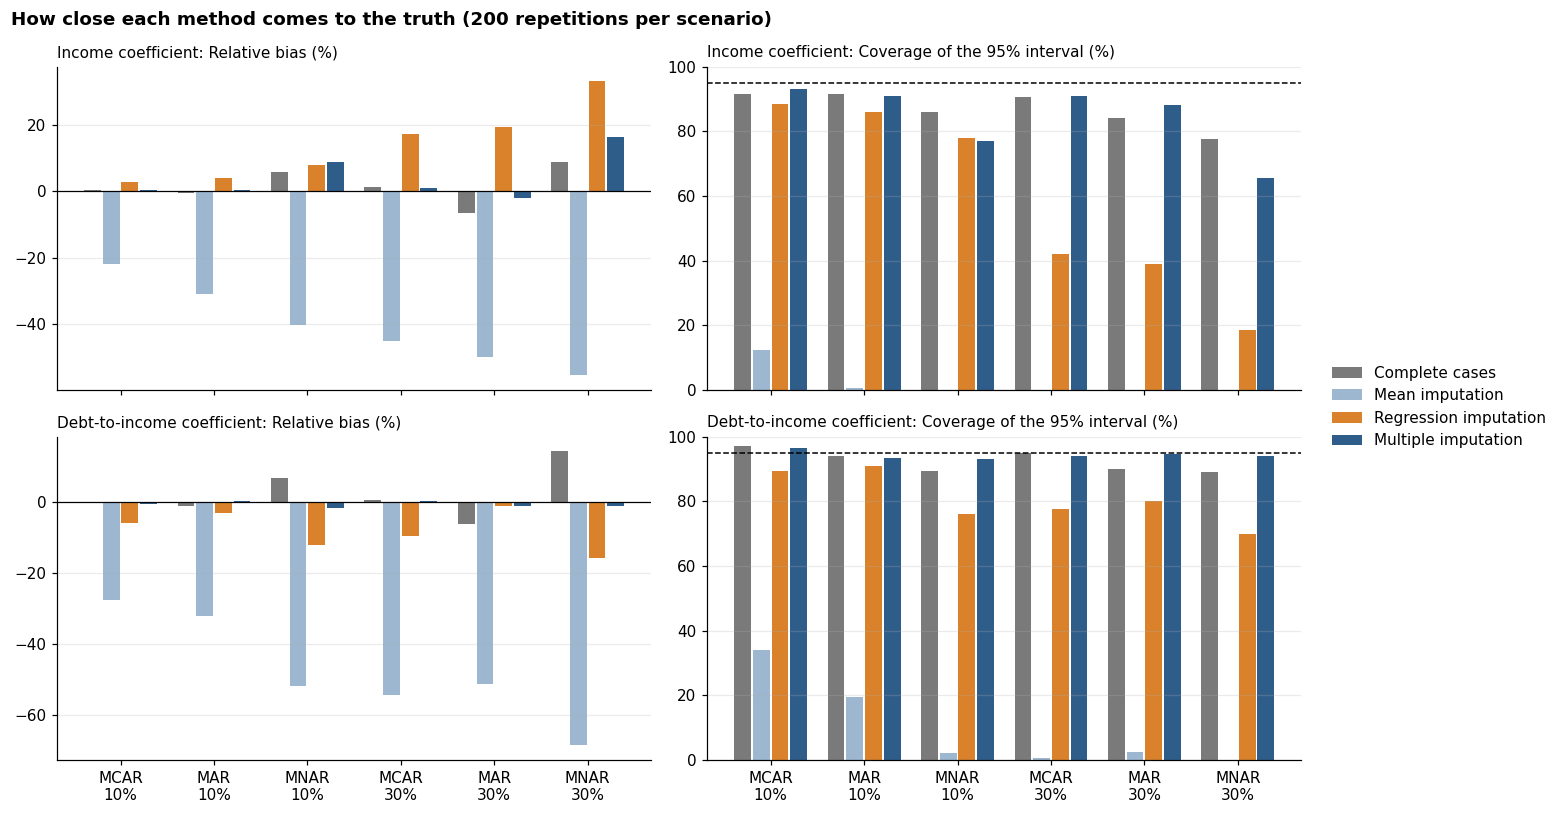

In [14]:
# Bias and coverage of each method, for each scenario and coefficient
SCENARIOS = [(r, m) for r in RATES for m in MECHANISMS]
LABELS = [f"{m}\n{r:.0%}" for r, m in SCENARIOS]
METHOD_COLORS = {"Complete cases": GREY, "Mean imputation": LIGHT_BLUE,
                 "Regression imputation": ORANGE, "Multiple imputation": BLUE}
FIELD_NAMES = {"log_income": "Income coefficient", "dti": "Debt-to-income coefficient"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
x = np.arange(len(SCENARIOS))
width = 0.2
for row, field in enumerate(GAP_FIELDS):
    s = summary[summary["field"] == field].set_index(["rate", "mechanism", "method"])
    for col, (measure, title) in enumerate([("relative bias (%)", "Relative bias (%)"),
                                            ("coverage (%)", "Coverage of the 95% interval (%)")]):
        ax = axes[row, col]
        for k, (method, color) in enumerate(METHOD_COLORS.items()):
            vals = [s.loc[(r, m, method), measure] for r, m in SCENARIOS]
            ax.bar(x + (k - 1.5) * width, vals, width * 0.9, color=color, label=method)
        if col == 0:
            ax.axhline(0, color="black", lw=0.8)
        else:
            ax.axhline(95, color="black", ls="--", lw=1)
            ax.set_ylim(0, 100)
        ax.set_title(f"{FIELD_NAMES[field]}: {title}", fontsize=10, loc="left")
        ax.set_xticks(x, LABELS)
        ax.grid(axis="x", visible=False)

# One legend for the four methods, at the right and centered
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.suptitle("How close each method comes to the truth (200 repetitions per scenario)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

The chart shows the pattern of the tables at a glance. The blue bars of multiple imputation stay near zero bias and near the 95% line in every scenario except one: the income coefficient under MNAR, where its bias grows and its coverage falls as the gap rate rises. The light blue bars of mean imputation are the largest biases in every scenario and almost never reach the 95% line. The orange bars of regression imputation lose coverage as the gaps grow, most of all for the income. The grey bars of complete cases stay close to the truth under MCAR, but drift under MAR at 30% and under MNAR.

## Summary of Chapter 2: The test

**Question:** Which way of handling the gaps recovers the true result?

**Answer:** Multiple imputation. When the gaps depend on observed information, it recovers both coefficients within 2.0% of the truth and has the smallest error. The common shortcuts distort the benchmark, and complete cases loses accuracy as the gaps grow. When a gap depends on the missing income itself, no method recovers the income coefficient.

**What the evidence shows:**
- **Design.** 1,200 samples of 5,000 loans from a truth set of 98,583 complete loans, with values removed from the income and the debt-to-income ratio under three mechanisms at 10% and 30%, and four methods applied to each sample.
- **Multiple imputation.** Relative bias within 2.0% under MCAR and MAR for both coefficients, and the lowest relative RMSE in all those cases. Coverage of 93.0% to 96.5% for the debt-to-income coefficient in every scenario, and slightly low for the income, from 88.0% to 93.0% under MCAR and MAR.
- **Complete cases.** Unbiased under MCAR, but about 6% low for both coefficients with 30% of values missing at random, with an income coverage of 84.0%.
- **Shortcuts.** Mean imputation shrinks the coefficients by 22% to 69% and almost never covers the truth. Regression imputation overstates the income coefficient by up to 33% and its coverage falls as low as 18.5%.
- **Missing not at random.** For the income, multiple imputation is off by 8.8% and 16.4% at the two rates, and complete cases by 5.8% and 8.8%. For the debt-to-income ratio, multiple imputation stays within 1.7% of the truth.

**What this means for a pricing team:** filling gaps with an average, a common step in spreadsheets and dashboards, can cut the measured effect of income and debt on the rate by a quarter to more than half. Multiple imputation, with the rate and the variables that predict the gaps in its model, is the safe default. Its result for the income still rests on the assumption that the gaps are not tied to the income itself, so Chapter 3 tests how far that assumption can move the benchmark.

# Chapter 3: The benchmark

**Question:** How much does a pricing benchmark change with each choice?

**Why it matters:** Chapter 2 showed which method recovers the truth in a test. On real loans the truth is unknown, so the question becomes practical: how far apart are the benchmarks a team would get with each method, and how much would the conclusion move if the income gaps were linked to the income itself.

## 3.1 Design

| Choice | Decision | Why |
|---|---|---|
| Loans | The loans of the population with an interest rate | A pricing benchmark needs a price. Imputing the rate itself would add invented prices to the outcome, and most loans without a rate are the records withheld by their lender |
| Benchmark | The model of Chapter 2: the rate on the log income, the debt-to-income ratio, the loan-to-value ratio and the log loan amount, with the loan type and manufactured homes as controls | The same model keeps the real results comparable with the test |
| Main benchmark | Site-built homes, with manufactured homes reported separately from section 3.4 on | Section 3.3 shows that the two markets price differently, and that mixing them in one model makes the result depend on how many manufactured homes each method keeps |
| Fields with gaps | The income, the debt-to-income ratio and the loan-to-value ratio | These are the predictors with gaps in the real data. The loan-to-value ratio is added to the two fields of the test because it has the largest gap |
| Zero incomes | Treated as missing | The logarithm of zero is not defined, and notebook 1 kept them flagged for the analysis to decide |
| Flagged lender | Its incomes treated as missing in the main benchmark, and kept as reported in a comparison | Notebook 1 found that its incomes are likely in the wrong unit, and the comparison shows what that error would do to the benchmark |
| Methods | All four methods of Chapter 2, with multiple imputation as the reference | Chapter 2 says which method to trust; the real data show how far apart the others land |
| Imputations | 20 completed versions | At least as many as the percentage of incomplete loans, the usual rule for a stable result |
| Missing not at random | Imputed log incomes shifted by an amount delta, from -1 to +1 | The test showed that the income coefficient is the one exposed to this case. A shift of 1 in log income means imputed incomes 2.7 times higher than missing at random would predict, a deliberately extreme range |

## 3.2 The loans of the benchmark

The cell builds the table of the benchmark from the population: it keeps the loans with an interest rate, takes the logarithms of the income and the loan amount, and treats zero incomes and the flagged lender's incomes as missing. It then counts the gaps left in each field.

In [15]:
# Loans of the population with an interest rate
has_rate = pop["interest_rate_clean"].notna()
b_src = pop[has_rate]

# Income for the benchmark: zero incomes and the flagged lender's incomes become missing
income_used = b_src["income_clean"].mask((b_src["income_clean"] == 0) | b_src["flag_income_unit_lender"])

bench = pd.DataFrame({
    "rate": b_src["interest_rate_clean"],
    "log_income": np.log(income_used),
    "dti": b_src["dti_mid"],
    "ltv": b_src["loan_to_value_ratio_clean"],
    "log_loan": np.log(b_src["loan_amount_clean"]),
    "loan_type": b_src["loan_type"],
    "manufactured": b_src["manufactured"].astype(int),
}).reset_index(drop=True)

# Gaps left in each field, and the share of incomplete loans
REAL_GAPS = ["log_income", "dti", "ltv"]
print(f"Loans with an interest rate: {len(bench):,} of {len(pop):,}")
print(f"  zero incomes treated as missing: {(b_src['income_clean'] == 0).sum():,}")
print(f"  flagged lender's incomes treated as missing: {(b_src['flag_income_unit_lender'] & b_src['income_clean'].notna() & (b_src['income_clean'] != 0)).sum():,}\n")
gaps_b = bench[REAL_GAPS].isna().sum().rename("missing").to_frame()
gaps_b["share (%)"] = gaps_b["missing"] / len(bench) * 100
print(gaps_b.to_string(formatters={"missing": "{:,}".format, "share (%)": "{:.2f}".format}))
incomplete_b = bench[REAL_GAPS].isna().any(axis=1)
print(f"\nIncomplete loans: {incomplete_b.sum():,} ({incomplete_b.mean() * 100:.1f}%)")

Loans with an interest rate: 106,546 of 108,384
  zero incomes treated as missing: 121
  flagged lender's incomes treated as missing: 380

           missing share (%)
log_income   1,712      1.61
dti            728      0.68
ltv          5,709      5.36

Incomplete loans: 7,838 (7.4%)


The benchmark uses 106,546 loans, the 108,384 of the population minus the 1,838 without an interest rate. The income is missing in 1,712 loans (1.61%), including 121 zero incomes and 380 incomes of the flagged lender treated as missing, the debt-to-income ratio in 728 (0.68%) and the loan-to-value ratio in 5,709 (5.36%). In all, 7,838 loans (7.4%) lack at least one of the three fields, so 20 imputations meet the rule of at least one imputation per percentage point of incomplete loans.

## 3.3 The benchmark under each method

The four methods of Chapter 2 are applied to the 106,546 loans, now with gaps in three fields. Regression imputation predicts each field from the variables that are always observed: the rate, the loan size, the loan type and the construction. Multiple imputation creates 20 completed versions, imputing each field in turn from those variables and from the current values of the other two, over ten cycles. The function also accepts a shift delta for the imputed incomes, which section 3.5 uses; here it is zero. The table shows the four main coefficients under each method, and how far each lands from multiple imputation.

In [16]:
# A separate random generator, so this chapter gives the same numbers whether or not Chapter 2 is run
rng3 = np.random.default_rng(SEED)
COEFS = {"log_income": 1, "dti": 2, "ltv": 3, "log_loan": 4}   # positions in the design matrix

def fit_all(d):
    b, se, df_res = ols(design(d), d["rate"].to_numpy())
    idx = list(COEFS.values())
    return b[idx], se[idx], np.full(len(idx), float(df_res))

# Variables always observed in the real data: the rate, the loan size, the loan type and the construction
def observed_base(d):
    lt = d["loan_type"].to_numpy()
    return np.column_stack([np.ones(len(d)), d["rate"], d["log_loan"],
                            lt == "2", lt == "3", lt == "4", d["manufactured"]]).astype(float)

def cc_real(g):
    return fit_all(g.dropna(subset=REAL_GAPS))

def mean_real(g):
    return fit_all(g.fillna({f: g[f].mean() for f in REAL_GAPS}))

def regression_real(g):
    d, Z = g.copy(), observed_base(g)
    for f in REAL_GAPS:
        obs = g[f].notna().to_numpy()
        coef = np.linalg.lstsq(Z[obs], g.loc[obs, f], rcond=None)[0]
        d.loc[~obs, f] = Z[~obs] @ coef
    return fit_all(d)

def mi_real(g, rng, m=20, iterations=10, delta=0.0):
    base = observed_base(g)
    masks = {f: g[f].isna().to_numpy() for f in REAL_GAPS}
    est, var = [], []
    for _ in range(m):
        cur = {f: g[f].fillna(g[f].mean()).to_numpy(copy=True) for f in REAL_GAPS}
        for _ in range(iterations):
            for f in REAL_GAPS:
                Z = np.column_stack([base] + [cur[o] for o in REAL_GAPS if o != f])   # the other two fields too
                obs, mis = ~masks[f], masks[f]
                V = np.linalg.pinv(Z[obs].T @ Z[obs])
                b_hat = V @ Z[obs].T @ cur[f][obs]
                resid = cur[f][obs] - Z[obs] @ b_hat
                s2 = resid @ resid / rng.chisquare(obs.sum() - Z.shape[1])
                b = rng.multivariate_normal(b_hat, s2 * V)
                cur[f][mis] = Z[mis] @ b + rng.normal(0, np.sqrt(s2), mis.sum())
                if f == "log_income":
                    cur[f][mis] += delta                                          # shift for section 3.5
        d = g.copy()
        for f in REAL_GAPS:
            d[f] = cur[f]
        q, se, df_c = fit_all(d)
        est.append(q); var.append(se ** 2)
    # Rubin's rules with the degrees of freedom of Barnard and Rubin (1999)
    est, var = np.array(est), np.array(var)
    q_mi, w, b_var = est.mean(axis=0), var.mean(axis=0), est.var(axis=0, ddof=1)
    total = w + (1 + 1 / m) * b_var
    lam = (1 + 1 / m) * b_var / total
    df_mi = 1 / (1 / ((m - 1) / lam ** 2) + 1 / ((df_c + 1) / (df_c + 3) * df_c * (1 - lam)))
    return q_mi, np.sqrt(total), df_mi

# The benchmark under each method
results = {"Complete cases": cc_real(bench), "Mean imputation": mean_real(bench),
           "Regression imputation": regression_real(bench), "Multiple imputation": mi_real(bench, rng3)}
real = pd.DataFrame({name: r[0] for name, r in results.items()}, index=list(COEFS))
real["MI std. error"] = results["Multiple imputation"][1]
print(real.round(4).to_string(), "\n")

# Distance of each method from multiple imputation, as a percentage of the multiple imputation estimate
diff = real[["Complete cases", "Mean imputation", "Regression imputation"]].sub(real["Multiple imputation"], axis=0)
print((diff.div(real["Multiple imputation"], axis=0) * 100).round(1).add_suffix(" vs MI (%)").to_string())

            Complete cases  Mean imputation  Regression imputation  Multiple imputation  MI std. error
log_income          0.3899           0.4373                 0.4777               0.4799         0.0069
dti                 0.0102           0.0126                 0.0134               0.0136         0.0003
ltv                 0.0071           0.0080                 0.0086               0.0084         0.0002
log_loan           -0.4680          -0.5761                -0.6258              -0.6281         0.0079 

            Complete cases vs MI (%)  Mean imputation vs MI (%)  Regression imputation vs MI (%)
log_income                     -18.7                       -8.9                             -0.5
dti                            -24.6                       -7.0                             -0.9
ltv                            -15.7                       -4.7                              2.5
log_loan                       -25.5                       -8.3                             -0.

The benchmark depends heavily on how the gaps are handled. Complete cases gives an income coefficient of 0.3899, while multiple imputation gives 0.4799: the complete-case estimate is 18.7% lower, and the same holds for the other coefficients, from 15.7% lower for the loan-to-value ratio to 25.5% for the loan size. The difference in the income coefficient is about 13 times its standard error, so it is not chance. Regression imputation lands within 2.5% of multiple imputation, and mean imputation between the two.

Mean imputation shrank every coefficient in Chapter 2, yet here it moves them away from complete cases in the same direction as multiple imputation. Filling a gap with a constant cannot strengthen a relation, so the change comes mainly from the loans that complete cases leaves out. The 7,838 incomplete loans relate the rate to the borrower and the loan differently from the rest, and Chapter 1 showed they concentrate in manufactured homes, VA loans and certain lenders.

### Where the difference comes from

Two explanations are possible. If loans that complete cases leaves out are priced differently, the difference should shrink when those loans are set aside; manufactured homes are the first candidate, since 37.40% of them lack the loan-to-value ratio. If instead the imputation model misses the lender, which predicted the gaps best in Chapter 1, the difference should shrink when the lender enters the model. The cell refits complete cases and multiple imputation on site-built homes only, and on all loans with the lender's average rate added to the imputation model. The lender's average leaves out the loan itself, as in Chapter 1.

In [17]:
# Multiple imputation with optional extra predictors in the imputation model
def mi_real_extra(g, rng, extra, m=20, iterations=10):
    base = np.column_stack([observed_base(g), extra])
    masks = {f: g[f].isna().to_numpy() for f in REAL_GAPS}
    est, var = [], []
    for _ in range(m):
        cur = {f: g[f].fillna(g[f].mean()).to_numpy(copy=True) for f in REAL_GAPS}
        for _ in range(iterations):
            for f in REAL_GAPS:
                Z = np.column_stack([base] + [cur[o] for o in REAL_GAPS if o != f])
                obs, mis = ~masks[f], masks[f]
                V = np.linalg.pinv(Z[obs].T @ Z[obs])
                b_hat = V @ Z[obs].T @ cur[f][obs]
                resid = cur[f][obs] - Z[obs] @ b_hat
                s2 = resid @ resid / rng.chisquare(obs.sum() - Z.shape[1])
                b = rng.multivariate_normal(b_hat, s2 * V)
                cur[f][mis] = Z[mis] @ b + rng.normal(0, np.sqrt(s2), mis.sum())
        d = g.copy()
        for f in REAL_GAPS:
            d[f] = cur[f]
        q, se, df_c = fit_all(d)
        est.append(q); var.append(se ** 2)
    est, var = np.array(est), np.array(var)
    return est.mean(axis=0), np.sqrt(var.mean(axis=0) + (1 + 1 / m) * est.var(axis=0, ddof=1))

# The lender's average rate over its other loans (the loan itself left out)
lei_b = b_src["lei"].to_numpy()
by_lei = bench["rate"].groupby(lei_b)
others = by_lei.transform("size") - 1
lender_rate = ((by_lei.transform("sum") - bench["rate"]) / others.replace(0, np.nan)).fillna(bench["rate"].mean())

# Site-built homes only
site = bench[bench["manufactured"] == 0].reset_index(drop=True)

checks = {
    ("All loans", "Complete cases"): cc_real(bench)[0],
    ("All loans", "Multiple imputation"): results["Multiple imputation"][0],
    ("Site-built only", "Complete cases"): cc_real(site)[0],
    ("Site-built only", "Multiple imputation"): mi_real(site, rng3)[0],
    ("All loans, lender in the model", "Multiple imputation"): mi_real_extra(bench, rng3, lender_rate.to_numpy())[0],
}
check_tab = pd.DataFrame(checks, index=list(COEFS)).T
print(check_tab.round(4).to_string(), "\n")
print(f"Site-built loans: {len(site):,} | incomplete among them: {site[REAL_GAPS].isna().any(axis=1).sum():,}")
print(f"Manufactured loans: {len(bench) - len(site):,} | incomplete among them: "
      f"{bench.loc[bench['manufactured'] == 1, REAL_GAPS].isna().any(axis=1).sum():,}")

                                                    log_income     dti     ltv  log_loan
All loans                      Complete cases           0.3899  0.0102  0.0071   -0.4680
                               Multiple imputation      0.4799  0.0136  0.0084   -0.6281
Site-built only                Complete cases           0.3785  0.0102  0.0067   -0.4441
                               Multiple imputation      0.3789  0.0102  0.0069   -0.4476
All loans, lender in the model Multiple imputation      0.4789  0.0136  0.0081   -0.6262 

Site-built loans: 101,554 | incomplete among them: 5,879
Manufactured loans: 4,992 | incomplete among them: 1,959


Manufactured homes explain the difference, and the lender does not. On site-built homes alone, complete cases and multiple imputation give almost the same benchmark: an income coefficient of 0.3785 against 0.3789, and a loan size coefficient of -0.4441 against -0.4476. Adding the lender's average rate to the imputation model leaves the result on all loans practically unchanged, 0.4789 against 0.4799 for the income.

Manufactured homes are 4,992 of the 106,546 loans, but 1,959 of them (39.2%) are incomplete, against 5,879 (5.8%) of site-built homes. The benchmark gives them their own level of rates but the same slopes as site-built homes. Complete cases leaves out two in five of them, while multiple imputation keeps them all, so the slopes it estimates lean more towards how manufactured homes are priced. The handling method changes the benchmark because it changes the mix of two markets that price differently.

## 3.4 Two benchmarks

From here on, the main benchmark covers site-built homes, and manufactured homes get their own. The cell applies the four methods to each group. For site-built homes, 5.8% of the loans are incomplete; for manufactured homes, 39.2%, so the choice of method matters far more there.

In [18]:
# Manufactured homes only
manuf = bench[bench["manufactured"] == 1].reset_index(drop=True)

# The four methods on each group, with the multiple imputation standard error
two = {}
for group, data_g in [("Site-built", site), ("Manufactured", manuf)]:
    res = {"Complete cases": cc_real(data_g), "Mean imputation": mean_real(data_g),
           "Regression imputation": regression_real(data_g), "Multiple imputation": mi_real(data_g, rng3)}
    t = pd.DataFrame({name: r[0] for name, r in res.items()}, index=list(COEFS))
    t["MI std. error"] = res["Multiple imputation"][1]
    two[group] = t
    print(f"{group} homes: {len(data_g):,} loans")
    print(t.round(4).to_string(), "\n")
site_mi = two["Site-built"]["Multiple imputation"]

Site-built homes: 101,554 loans
            Complete cases  Mean imputation  Regression imputation  Multiple imputation  MI std. error
log_income          0.3785           0.3446                 0.3778               0.3792         0.0067
dti                 0.0102           0.0096                 0.0102               0.0102         0.0003
ltv                 0.0067           0.0061                 0.0069               0.0069         0.0002
log_loan           -0.4441          -0.4037                -0.4463              -0.4480         0.0077 

Manufactured homes: 4,992 loans
            Complete cases  Mean imputation  Regression imputation  Multiple imputation  MI std. error
log_income          0.5276           0.6972                 0.6677               0.7275         0.0476
dti                 0.0068           0.0209                 0.0187               0.0203         0.0018
ltv                 0.0202           0.0455                 0.0669               0.0457         0.0021
log_loa

For site-built homes, the method barely matters. Complete cases, regression imputation and multiple imputation agree within 2.9% on every coefficient, and the income coefficient differs by 0.0007 between complete cases and multiple imputation, a tenth of its standard error. Only mean imputation moves away, shrinking the coefficients by 5.9% to 11.6%, as it did in the test of Chapter 2. With 5.8% of the loans incomplete and gaps that follow observed information, a team pricing site-built homes reaches the same benchmark with complete cases or with multiple imputation.

For manufactured homes, the method changes the answer. Complete cases gives an income coefficient of 0.5276 against 0.7275 with multiple imputation, 27.5% lower and about 4 standard errors away, and the gap is larger for the debt-to-income ratio (66.5% lower) and the loan-to-value ratio (55.8% lower). With 39.2% of these loans incomplete, dropping them changes which manufactured homes the benchmark describes. Regression imputation also drifts, overstating the loan-to-value coefficient by 46.4%.

The two markets also price differently. Under multiple imputation, the rate of a manufactured home moves about twice as much with income and with the debt-to-income ratio as that of a site-built home, three times as much with loan size, and more than six times as much with the loan-to-value ratio.

## 3.5 If the missing incomes were different

Multiple imputation assumes that the missing incomes follow the same pattern as the observed ones, given everything else the model sees. The test of

In [19]:
# Shifts of the imputed log incomes, from 2.7 times lower to 2.7 times higher
DELTAS = [-1.0, -0.5, -0.25, 0.0, 0.25, 0.5, 1.0]
print(f"Site-built loans with a missing income: {site['log_income'].isna().sum():,} "
      f"({site['log_income'].isna().mean() * 100:.2f}%)\n")

# Refit the site-built benchmark with multiple imputation for each shift
rows = []
for delta in DELTAS:
    q, se, df_d = mi_real(site, rng3, delta=delta)
    t = sps.t.ppf(0.975, df_d[0])
    rows.append({"delta": delta, "income multiplier": np.exp(delta), "income coefficient": q[0],
                 "95% low": q[0] - t * se[0], "95% high": q[0] + t * se[0]})
    print(f"delta {delta:+.2f}: done")

sens = pd.DataFrame(rows).set_index("delta")
base_q = sens.loc[0.0, "income coefficient"]
sens["outside the interval"] = (base_q < sens["95% low"]) | (base_q > sens["95% high"])
print()
print(sens.round(4).to_string())

Site-built loans with a missing income: 1,692 (1.67%)

delta -1.00: done
delta -0.50: done
delta -0.25: done
delta +0.00: done
delta +0.25: done
delta +0.50: done
delta +1.00: done

       income multiplier  income coefficient  95% low  95% high  outside the interval
delta                                                                                
-1.00             0.3679              0.3076   0.2952    0.3200                  True
-0.50             0.6065              0.3524   0.3396    0.3653                  True
-0.25             0.7788              0.3696   0.3565    0.3827                 False
 0.00             1.0000              0.3783   0.3653    0.3913                 False
 0.25             1.2840              0.3820   0.3691    0.3950                 False
 0.50             1.6487              0.3783   0.3654    0.3911                 False
 1.00             2.7183              0.3538   0.3416    0.3661                  True


The site-built benchmark holds up well. Only 1,692 site-built loans (1.67%) lack an income, so the shift touches a small share of the data. Without a shift, the income coefficient is 0.3783. It stays inside its own interval if the missing incomes are up to 22% lower or up to 65% higher than the imputation predicts. The tipping point lies between a shift of -0.25 and -0.5 on the low side, missing incomes between 22% and 39% lower, and between +0.5 and +1 on the high side, missing incomes between 65% and 172% higher.

Even at the extremes the conclusion does not reverse. With missing incomes 2.7 times lower, the coefficient falls to 0.3076, 18.7% below the unshifted value, and with incomes 2.7 times higher it falls to 0.3538, 6.5% below. In every case it stays positive and its interval stays far from zero. The effect is not monotonic: very low or very high imputed incomes both weaken the coefficient, because they place loans far from the others on income without a matching difference in their rates.

## 3.6 What the unit error would do

The main benchmark treats the incomes of the flagged lender as missing, because notebook 1 found that most of them look like amounts in dollars instead of thousands. This section puts them back as reported, including those above 10 million dollars, and refits the site-built benchmark with complete cases and with multiple imputation. The comparison shows how much a single lender's reporting error would move a benchmark built without an audit.

In [20]:
# Site-built loans in the order of the benchmark table
site_src = b_src[~b_src["manufactured"]]
flag = site_src["flag_income_unit_lender"]

# Incomes of the main benchmark, and the same incomes with the flagged lender's values as reported (positive ones)
inc_main = site_src["income_clean"].mask((site_src["income_clean"] == 0) | flag)
inc_reported = inc_main.where(~flag, site_src["income"].where(site_src["income"] > 0))
site_rep = site.copy()
site_rep["log_income"] = np.log(inc_reported).to_numpy()

print(f"Site-built loans of the flagged lender: {flag.sum():,} | "
      f"incomes put back: {inc_reported[flag].notna().sum():,} | "
      f"of which above 10 million dollars: {(inc_reported[flag] > 10_000).sum():,}\n")

# Main benchmark against the benchmark with the reported incomes
compare = pd.DataFrame({
    ("Main", "Complete cases"): two["Site-built"]["Complete cases"],
    ("Main", "Multiple imputation"): two["Site-built"]["Multiple imputation"],
    ("Reported incomes", "Complete cases"): cc_real(site_rep)[0],
    ("Reported incomes", "Multiple imputation"): mi_real(site_rep, rng3)[0],
}).T
print(compare.round(4).to_string())

Site-built loans of the flagged lender: 985 | incomes put back: 985 | of which above 10 million dollars: 620

                                      log_income     dti     ltv  log_loan
Main             Complete cases           0.3785  0.0102  0.0067   -0.4441
                 Multiple imputation      0.3792  0.0102  0.0069   -0.4480
Reported incomes Complete cases           0.1449  0.0052  0.0057   -0.2320
                 Multiple imputation      0.1486  0.0054  0.0058   -0.2398


One lender's error is enough to distort the benchmark more than any choice of method. The flagged lender has 985 site-built loans, 0.97% of the 101,554, and 620 of its incomes put back are above 10 million dollars. With them, the income coefficient falls from 0.3785 to 0.1449 with complete cases, 61.7% lower, and from 0.3792 to 0.1486 with multiple imputation, 60.8% lower. The error spreads to the other coefficients through their link with income: the debt-to-income coefficient falls by 47% to 49%, the loan size coefficient by 47% to 48%, and the loan-to-value coefficient by 15% to 16%.

Both methods move together because the problem is not a gap but a wrong value that looks present. No method for missing data can correct it; only an audit that finds it and sets it aside, as notebook 1 did.

## Summary of Chapter 3: The benchmark

**Question:** How much does a pricing benchmark change with each choice?

**Answer:** For site-built homes, very little. Complete cases and multiple imputation agree within 2.9% on every coefficient, and the income result survives large departures from the assumption behind the imputation. The choices that do change the benchmark are two others: mixing manufactured homes with site-built homes in one model, and keeping a lender's incomes reported in the wrong unit.

**What the evidence shows:**
- **All loans together.** On the 106,546 loans with a rate, complete cases gives an income coefficient 18.7% lower than multiple imputation, about 13 standard errors. Manufactured homes explain the difference: 39.2% of them are incomplete, against 5.8% of site-built homes, and on site-built homes alone the two methods agree.
- **Site-built homes.** On 101,554 loans, complete cases, regression imputation and multiple imputation agree within 2.9%; mean imputation shrinks the coefficients by 5.9% to 11.6%.
- **Manufactured homes.** On 4,992 loans, complete cases understates the coefficients by 27.5% to 66.5% against multiple imputation, and their rates respond about twice as much to income and debt as those of site-built homes, three times as much to loan size and more than six times as much to the loan-to-value ratio.
- **If the missing incomes were different.** The site-built income coefficient (0.3783) stays inside its interval for missing incomes up to 22% lower or 65% higher than imputed, and stays positive and far from zero even at 2.7 times lower or higher.
- **The unit error.** Putting back the flagged lender's incomes, 985 loans and 0.97% of site-built homes, cuts the income coefficient by about 61% under both methods.

**What this means for a pricing team:** the first decision is not the imputation method but the comparison group. A benchmark that pools site-built and manufactured homes gives a different answer depending on how many incomplete manufactured loans each method keeps; separate benchmarks remove that problem. For site-built homes, complete cases is an acceptable shortcut here because the gaps are few and follow observed information, while multiple imputation is the method that keeps manufactured homes honest. Above both, the audit matters most: one lender's unit error moves the benchmark further than any handling choice.

# Chapter 4: The outliers

**Question:** Which loans drive the results?

**Why it matters:** A benchmark fitted on 100,000 loans can still be steered by a few hundred of them. The chapter looks for loans that are unusual in their characteristics, loans that pull the fitted line towards themselves, and checks how much the benchmark moves when their weight is limited.

## 4.1 Design

| Choice | Decision | Why |
|---|---|---|
| Loans | The complete site-built loans | The diagnostics need every value present, and Chapter 3 showed that on site-built homes complete cases and multiple imputation give the same benchmark |
| Benchmark | The model of Chapters 2 and 3 | The influence measures describe the benchmark the earlier chapters estimated |
| Unusual characteristics | Classic and robust Mahalanobis distances on the log income, the debt-to-income ratio, the loan-to-value ratio and the log loan amount, with the 97.5% chi-square cutoff | These are the four predictors of the benchmark, with the amounts in logs to bring them closer to normal. The robust distance uses the minimum covariance determinant, which unusual loans cannot pull towards themselves |
| Cutoffs | The usual rules (2p/n for leverage, 4/n for Cook's distance, 2/√n for DFBETAS) used to count, and the loans with the largest values used to judge | With about 100,000 loans the rules flag thousands of ordinary loans, so the question is whether the most extreme ones change the result |
| Influence test | Refit the benchmark without the 0.1% and the 1% of loans with the largest Cook's distance | Shows whether the conclusions depend on a small group of loans |
| Robust fit | Huber regression against least squares | Limits the weight of loans with large residuals without removing any, and shows which loans the robust fit discounts |

## 4.2 Unusual combinations of characteristics

A loan can look ordinary in each field and still be unusual in their combination, such as a small income with a large loan. The Mahalanobis distance measures how far each loan lies from the center of the data, taking the spread and the correlations into account. Computed with the ordinary mean and covariance, unusual loans can hide each other by stretching the reference; the robust version estimates the center and the spread from the most concentrated part of the data, so it is not pulled by them. Loans beyond the 97.5% cutoff of the chi-square distribution with four degrees of freedom are flagged.

In [21]:
# Complete site-built loans and the four predictors of the benchmark
cc_site = site.dropna(subset=REAL_GAPS).reset_index(drop=True)
PRED = ["log_income", "dti", "ltv", "log_loan"]
Z = cc_site[PRED].to_numpy()

# Classic distance (ordinary mean and covariance) and robust distance (minimum covariance determinant)
diff = Z - Z.mean(axis=0)
d2_classic = np.einsum("ij,jk,ik->i", diff, np.linalg.inv(np.cov(Z, rowvar=False)), diff)
mcd = MinCovDet(random_state=SEED).fit(Z)
d2_robust = mcd.mahalanobis(Z)
cutoff = sps.chi2.ppf(0.975, len(PRED))

# Loans flagged by each distance
flag_classic, flag_robust = d2_classic > cutoff, d2_robust > cutoff
print(f"Complete site-built loans: {len(cc_site):,} | cutoff (chi-square, 4 df, 97.5%): {cutoff:.2f}")
print(f"Flagged by the classic distance: {flag_classic.sum():,} ({flag_classic.mean() * 100:.1f}%)")
print(f"Flagged by the robust distance:  {flag_robust.sum():,} ({flag_robust.mean() * 100:.1f}%)")
print(f"Flagged by both: {(flag_classic & flag_robust).sum():,} | only by the robust distance: "
      f"{(flag_robust & ~flag_classic).sum():,} | only by the classic: {(flag_classic & ~flag_robust).sum():,}\n")

# Typical values of the loans in each group (incomes and loans back in thousands and dollars)
groups = pd.Series(np.select([flag_classic & flag_robust, flag_robust], ["both", "robust only"], "not flagged"))
profile = cc_site.assign(group=groups.to_numpy()).groupby("group").agg(
    loans=("rate", "size"), median_income=("log_income", lambda s: np.exp(s.median())),
    median_dti=("dti", "median"), median_ltv=("ltv", "median"),
    median_loan=("log_loan", lambda s: np.exp(s.median())), median_rate=("rate", "median"))
print(profile.round(2).to_string(formatters={"loans": "{:,}".format, "median_loan": "{:,.0f}".format}))

Complete site-built loans: 95,675 | cutoff (chi-square, 4 df, 97.5%): 11.14
Flagged by the classic distance: 5,667 (5.9%)
Flagged by the robust distance:  37,635 (39.3%)
Flagged by both: 5,667 | only by the robust distance: 31,968 | only by the classic: 0

             loans  median_income  median_dti  median_ltv median_loan  median_rate
group                                                                             
both         5,667          162.0        33.0       48.54     205,000         6.38
not flagged 58,040          100.0        44.0       96.50     325,000         6.25
robust only 31,968          133.0        38.0       80.00     345,000         6.50


The two distances disagree sharply. The classic distance flags 5,667 loans (5.9%), and the robust distance flags all of them plus 31,968 more, 37,635 in all (39.3%), far beyond the 2.5% expected under the cutoff. The loans flagged by both are unusual in a clear way: a median loan-to-value ratio of 48.54%, a large down payment, with a median income of 162,000 dollars against 100,000 for loans not flagged.

The loans flagged only by the robust distance are not. Their median loan-to-value ratio is 80.00%, the usual ratio of a conventional loan with a 20% down payment, while the loans the robust distance treats as the center have a median of 96.50%, the ratio of an FHA loan with the minimum down payment. The robust estimate is built from the most concentrated half of the loans, and many loans share exactly the same ratio, so the center it finds is a pile of identical values with almost no spread, and ordinary loans look far from it.

### Why the robust distance flags so many loans

Mortgage ratios pile up at a few exact values set by the products and their rules, such as the minimum down payment of each loan type. The next cell measures how much of the data sits on the most common values of the loan-to-value and debt-to-income ratios. It then refits the robust estimate with 75% and 90% of the loans in its core instead of about half, so that the core has to span more than one pile, and compares the share of loans each version flags with the 2.5% expected.

In [22]:
# How piled up the two ratios are: share of loans on their five most common exact values
for col in ["ltv", "dti"]:
    top = cc_site[col].value_counts().head(5)
    print(f"{col}: five most common values hold {top.sum() / len(cc_site) * 100:.1f}% of the loans")
    print("   " + ", ".join(f"{v:g} ({n / len(cc_site) * 100:.1f}%)" for v, n in top.items()))
print()

# Robust distance with a larger core: share of loans flagged and overlap with the classic distance
mcd_runs = {}
for frac in [0.75, 0.90]:
    mcd_f = MinCovDet(support_fraction=frac, random_state=SEED).fit(Z)
    flag_f = mcd_f.mahalanobis(Z) > cutoff
    mcd_runs[frac] = flag_f
    print(f"Core of {frac:.0%}: flagged {flag_f.sum():,} ({flag_f.mean() * 100:.1f}%) | "
          f"also flagged by the classic distance: {(flag_f & flag_classic).sum():,} | "
          f"classic flags it misses: {(flag_classic & ~flag_f).sum():,}")

ltv: five most common values hold 59.4% of the loans
   96.5 (18.1%), 80 (13.4%), 100 (12.5%), 95 (10.0%), 90 (5.5%)
dti: five most common values hold 51.5% of the loans
   33 (14.4%), 55 (13.9%), 25 (12.1%), 49 (6.5%), 48 (4.6%)

Core of 75%: flagged 17,078 (17.9%) | also flagged by the classic distance: 5,667 | classic flags it misses: 0
Core of 90%: flagged 15,388 (16.1%) | also flagged by the classic distance: 5,667 | classic flags it misses: 0


The two ratios are heavily piled up. Five exact values hold 59.4% of the loan-to-value ratios, led by 96.5 (18.1%), the FHA minimum down payment, and 80 (13.4%). For the debt-to-income ratio, five values hold 51.5%, and the three largest piles, 33, 55 and 25 (40.4% together), are the midpoints given to the HMDA bands in notebook 1, so part of this piling comes from how the ratio is reported.

A larger core does not fix the robust distance. With 75% of the loans in its core it flags 17.9%, and with 90% it still flags 16.1%, against the 2.5% expected. The chi-square cutoff assumes continuous data spread around one center, and loans piled on a handful of values are far from that. In every version, the 5,667 loans flagged by the classic distance are also flagged by the robust one, so the robust distance finds no hidden group that the classic one misses: the problem it guards against, unusual loans hiding each other, does not appear here. The 5,667 loans flagged by the classic distance are therefore the ones kept as unusual combinations, and the next sections measure whether they, or any other loans, actually move the benchmark.

## 4.3 Leverage and influence

The benchmark is fitted again on the complete site-built loans, without the term for manufactured homes, which is constant here. For each loan, three measures describe its role in the fit. The leverage shows how unusual its characteristics are, and so how much it could move the line. The studentized residual shows how far its rate is from what the benchmark predicts. Cook's distance combines both into the change in the fitted values when the loan is removed. The cell counts the loans beyond the usual cutoffs, measures how much of the total influence the most influential loans hold, and checks how many of them are among the 5,667 unusual combinations of section 4.2.

In [23]:
# Benchmark on the complete site-built loans (manufactured homes are not part of this group)
FORMULA_SITE = "rate ~ log_income + dti + ltv + log_loan + C(loan_type)"
fit_site = smf.ols(FORMULA_SITE, data=cc_site).fit()
X_s = fit_site.model.exog
n_s, p_s = X_s.shape

# Leverage: diagonal of the hat matrix, computed without building the full matrix
lev = np.einsum("ij,jk,ik->i", X_s, np.linalg.inv(X_s.T @ X_s), X_s)

# Externally studentized residual: each residual scaled by the error variance estimated without that loan
e = fit_site.resid.to_numpy()
s2 = fit_site.mse_resid
s2_out = ((n_s - p_s) * s2 - e ** 2 / (1 - lev)) / (n_s - p_s - 1)
t_ext = e / np.sqrt(s2_out * (1 - lev))

# Cook's distance: squared internally studentized residual times the leverage term
cook = (e ** 2 / (s2 * (1 - lev))) / p_s * lev / (1 - lev)

# Loans beyond the usual cutoffs
print(f"Loans: {n_s:,} | coefficients: {p_s}")
print(f"Leverage above 2p/n ({2 * p_s / n_s:.6f}): {(lev > 2 * p_s / n_s).sum():,}")
print(f"Studentized residual beyond 3 in absolute value: {(np.abs(t_ext) > 3).sum():,}")
print(f"Cook's distance above 4/n ({4 / n_s:.6f}): {(cook > 4 / n_s).sum():,} | above 1: {(cook > 1).sum():,} "
      f"| largest: {cook.max():.4f}\n")

# How concentrated the influence is: share of the total Cook's distance in the most influential loans
order_c = np.argsort(cook)[::-1]
for share in [0.001, 0.01]:
    k = int(round(share * n_s))
    top_k = order_c[:k]
    print(f"Top {share:.1%} ({k:,} loans): {cook[top_k].sum() / cook.sum() * 100:.1f}% of the total Cook's distance | "
          f"among the unusual combinations of 4.2: {flag_classic[top_k].sum():,}")

# Profile of the 100 most influential loans against the rest (income in thousands of dollars)
top100 = np.zeros(n_s, dtype=bool); top100[order_c[:100]] = True
prof = cc_site.assign(group=np.where(top100, "top 100", "others")).groupby("group").agg(
    median_rate=("rate", "median"), median_income=("log_income", lambda s: np.exp(s.median())),
    median_dti=("dti", "median"), median_ltv=("ltv", "median"),
    median_loan=("log_loan", lambda s: np.exp(s.median())))
print()
print(prof.round(2).to_string(formatters={"median_loan": "{:,.0f}".format}))

Loans: 95,675 | coefficients: 8
Leverage above 2p/n (0.000167): 5,412
Studentized residual beyond 3 in absolute value: 1,364
Cook's distance above 4/n (0.000042): 4,985 | above 1: 0 | largest: 0.0021

Top 0.1% (96 loans): 7.6% of the total Cook's distance | among the unusual combinations of 4.2: 64
Top 1.0% (957 loans): 25.2% of the total Cook's distance | among the unusual combinations of 4.2: 427

         median_rate  median_income  median_dti  median_ltv median_loan
group                                                                  
others          6.38          110.0        42.0        95.0     335,000
top 100         5.75           99.5        33.0        80.0     265,000


No single loan steers the benchmark. The largest Cook's distance is 0.0021, far below the level of 1 that marks a loan able to move the fit on its own, although 4,985 loans (5.21%) pass the screening cutoff of 4/n, as expected with this many loans. Leverage is high for 5,412 loans (5.66%), and 1,364 rates (1.43%) lie more than 3 standard errors from what the benchmark predicts, about five times the share a normal distribution would give, so the rates have heavier tails than the model assumes.

Influence is concentrated, though. The 96 most influential loans, 0.1% of the total, hold 7.6% of the total Cook's distance, and the top 1% hold 25.2%. The unusual combinations of section 4.2 are 5.92% of the loans but 64 of the top 96 and 427 of the top 957. The 100 most influential loans carry lower rates than the rest, a median of 5.75% against 6.38%, together with lower debt-to-income and loan-to-value ratios and smaller loans: well-qualified borrowers priced below what the benchmark expects.

## 4.4 What the most influential loans change

Two checks measure what the influential loans do to the benchmark. The first refits it without the 0.1% and the 1% of loans with the largest Cook's distance and compares the coefficients with those on all loans, in units of their standard error. The second uses DFBETAS, the change in each coefficient when a single loan is removed, also in units of its standard error, to see which coefficients the influential loans move. With about 95,000 loans, the usual cutoff of 2/√n flags many loans, so the largest values matter more than the count.

In [24]:
# Coefficients of the four predictors on all loans
KEY4 = ["log_income", "dti", "ltv", "log_loan"]
base_coef, base_se = fit_site.params[KEY4], fit_site.bse[KEY4]

# Refit without the 0.1% and the 1% most influential loans, and measure the change in standard errors
rows = {"All loans": base_coef}
for share in [0.001, 0.01]:
    k = int(round(share * n_s))
    keep_i = np.ones(n_s, dtype=bool); keep_i[order_c[:k]] = False
    rows[f"Without top {share:.1%} ({k:,})"] = smf.ols(FORMULA_SITE, data=cc_site[keep_i]).fit().params[KEY4]
refit = pd.DataFrame(rows).T
print(refit.round(4).to_string(), "\n")
print("Change from all loans, in standard errors:")
print(((refit - base_coef) / base_se).iloc[1:].round(2).to_string(), "\n")

# DFBETAS of every loan for the four predictors (exact formula, one fit)
XtX_inv = np.linalg.inv(X_s.T @ X_s)
cols = [fit_site.model.exog_names.index(c) for c in KEY4]
change = (X_s @ XtX_inv)[:, cols] * (e / (1 - lev))[:, None]       # change in each coefficient when the loan is removed
dfbetas = change / np.sqrt(s2_out[:, None] * np.diag(XtX_inv)[cols][None, :])

# Loans beyond 2/√n, the largest value, and how many of the beyond-cutoff loans are in the top 1% by Cook's distance
cut_db = 2 / np.sqrt(n_s)
top1 = np.zeros(n_s, dtype=bool); top1[order_c[:int(round(0.01 * n_s))]] = True
db = pd.DataFrame({
    "beyond 2/√n": (np.abs(dfbetas) > cut_db).sum(axis=0),
    "largest |DFBETAS|": np.abs(dfbetas).max(axis=0),
    "beyond cutoff and in top 1% Cook": ((np.abs(dfbetas) > cut_db) & top1[:, None]).sum(axis=0),
}, index=KEY4)
print(f"Cutoff 2/√n: {cut_db:.4f}")
print(db.to_string(formatters={"beyond 2/√n": "{:,}".format, "largest |DFBETAS|": "{:.4f}".format,
                               "beyond cutoff and in top 1% Cook": "{:,}".format}))

                        log_income     dti     ltv  log_loan
All loans                   0.3785  0.0102  0.0067   -0.4441
Without top 0.1% (96)       0.3874  0.0103  0.0067   -0.4509
Without top 1.0% (957)      0.3994  0.0104  0.0065   -0.4719 

Change from all loans, in standard errors:
                        log_income   dti   ltv  log_loan
Without top 0.1% (96)         1.33  0.14  0.00     -0.87
Without top 1.0% (957)        3.13  0.53 -1.51     -3.58 

Cutoff 2/√n: 0.0065
           beyond 2/√n largest |DFBETAS| beyond cutoff and in top 1% Cook
log_income       4,719            0.1267                              675
dti              5,325            0.0791                              624
ltv              4,318            0.0961                              555
log_loan         5,028            0.1189                              682


The most influential loans pull the income and loan size coefficients towards zero, but only by a few percent. Without the 96 most influential loans, the income coefficient rises from 0.3785 to 0.3874 (2.4%) and the debt-to-income and loan-to-value coefficients do not move. Without the top 1%, 957 loans, the income coefficient rises to 0.3994 (5.5%) and the loan size coefficient becomes 6.3% steeper, changes of 3.13 and 3.58 standard errors. With about 95,000 loans the standard errors are so small that a change of a few percent already spans several of them, so these shifts are clear statistically but modest for pricing.

DFBETAS tells the same story one loan at a time. Between 4.5% and 5.6% of the loans pass the cutoff of 2/√n for each coefficient, but the largest value is 0.1267, for the income: removing any single loan moves a coefficient by at most about an eighth of its standard error. Between 555 and 682 of the loans beyond the cutoff for each coefficient are among the top 1% by Cook's distance, so the same small group carries most of the influence.

## 4.5 A fit that limits extreme rates

Section 4.3 found more extreme rates than the model assumes. Huber regression handles them without removing any loan: it treats small residuals like least squares, but gives less weight to loans whose rate is far from the fitted value, using the usual constant of 1.345 standard deviations. The cell compares its coefficients with least squares and summarizes the weights it gives, which show how many loans it discounts and which ones.

In [25]:
# Huber regression on the same loans and the same model
huber = smf.rlm(FORMULA_SITE, data=cc_site, M=sm.robust.norms.HuberT(t=1.345)).fit()

# Coefficients of least squares and Huber, with the difference in percent and in least-squares standard errors
comp = pd.DataFrame({"least squares": base_coef, "Huber": huber.params[KEY4]})
comp["difference (%)"] = (comp["Huber"] - comp["least squares"]) / comp["least squares"] * 100
comp["difference (std. errors)"] = (comp["Huber"] - comp["least squares"]) / base_se
print(comp.to_string(formatters={"least squares": "{:.4f}".format, "Huber": "{:.4f}".format,
                                 "difference (%)": "{:.1f}".format, "difference (std. errors)": "{:.1f}".format}), "\n")

# Weights given by the Huber fit: how many loans it discounts, and how strongly
w = huber.weights.to_numpy()
print(f"Loans with full weight: {(w >= 0.9999).sum():,} ({(w >= 0.9999).mean() * 100:.1f}%)")
print(f"Loans with weight below 0.5: {(w < 0.5).sum():,} ({(w < 0.5).mean() * 100:.1f}%) | lowest weight: {w.min():.3f}")
print(f"Of the loans below 0.5, in the top 1% by Cook's distance: {((w < 0.5) & top1).sum():,}\n")

# Rates of the strongly discounted loans against the predicted rate
low = w < 0.5
pred = fit_site.fittedvalues.to_numpy()
print(f"Strongly discounted loans with a rate above the prediction: {(low & (cc_site['rate'].to_numpy() > pred)).sum():,} | "
      f"below: {(low & (cc_site['rate'].to_numpy() < pred)).sum():,}")

           least squares   Huber difference (%) difference (std. errors)
log_income        0.3785  0.3292          -13.0                     -7.4
dti               0.0102  0.0090          -11.7                     -4.3
ltv               0.0067  0.0063           -5.4                     -2.2
log_loan         -0.4441 -0.3839          -13.6                      7.8 

Loans with full weight: 76,486 (79.9%)
Loans with weight below 0.5: 3,807 (4.0%) | lowest weight: 0.137
Of the loans below 0.5, in the top 1% by Cook's distance: 698

Strongly discounted loans with a rate above the prediction: 1,271 | below: 2,536


Limiting the weight of extreme rates flattens the benchmark. Huber regression gives coefficients closer to zero than least squares for all four predictors: 13.0% lower for the income, 11.7% for the debt-to-income ratio, 5.4% for the loan-to-value ratio and 13.6% for the loan size, between 2.2 and 7.8 standard errors. It gives full weight to 79.9% of the loans and less than half the usual weight to 3,807 (4.0%), down to 0.137. These strongly discounted loans include 698 of the 957 most influential loans of section 4.3, and two thirds of them (2,536) carry a rate below what the benchmark predicts.

The two ways of limiting extreme loans move the coefficients in opposite directions. Removing the most influential 1% raises the income coefficient to 0.3994, while Huber regression lowers it to 0.3292, against 0.3785 for least squares on all loans. The benchmark is therefore not fixed to the third decimal: depending on how extreme loans are treated, the income coefficient moves within about 13% below and 6% above its least-squares value. The direction of every effect stays the same.

## Summary of Chapter 4: The outliers

**Question:** Which loans drive the results?

**Answer:** No single loan does. The influence that exists is spread over a small group of well-qualified borrowers with low rates, and limiting it shifts the coefficients by a few percent up to about 14%, always in the same direction. The site-built benchmark is stable in its message, though not to the third decimal.

**What the evidence shows:**
- **Unusual combinations.** The classic Mahalanobis distance flags 5,667 loans (5.92%), mostly large down payments. The robust version flags 16% to 39% of the loans because the ratios pile up on a few exact values, five of them holding 59.4% of the loan-to-value ratios, and it finds no loan the classic distance misses.
- **Single loans.** The largest Cook's distance is 0.0021, far below 1, and the largest DFBETAS is 0.1267: removing any one loan moves a coefficient by at most about an eighth of its standard error.
- **Small groups.** The 1% most influential loans hold 25.2% of the total Cook's distance and carry lower rates than the rest, a median of 5.75% against 6.38% for the top 100. Without them, the income coefficient rises by 5.5% and the loan size coefficient by 6.3%.
- **Heavy tails.** 1,364 rates lie more than 3 standard errors from the prediction, about five times the normal share. Huber regression discounts 20.1% of the loans and gives coefficients 5.4% to 13.6% closer to zero.

**What this means for a pricing team:** the benchmark is not driven by a handful of errors, so there is no need to hunt for and remove individual loans once the audit of notebook 1 is done. A team should, however, report the income and loan size effects as a range rather than a single number, since reasonable treatments of extreme rates move them by up to about 14%. The loans that pull hardest are borrowers priced well below the market average, a group worth studying on its own rather than discarding.

# Conclusions

**The default is safe for site-built homes, and only there.** Dropping incomplete loans gives the same pricing benchmark as multiple imputation for site-built homes, within 2.9% on every coefficient, because only 5.8% of them are incomplete and their gaps follow observed information. For manufactured homes, 39.2% of loans are incomplete, and dropping them understates the coefficients by 27.5% to 66.5%.

**The comparison group matters more than the method.** On all loans together, complete cases and multiple imputation disagree by 18.7% on the income coefficient. The disagreement disappears once site-built and manufactured homes are modelled apart, because manufactured home rates respond about twice as much to income and debt and more than six times as much to the loan-to-value ratio.

**Shortcuts fail in predictable ways.** In the test, filling gaps with the mean shrank the coefficients by 22% to 69%, and regression imputation overstated the income coefficient by up to 33% with intervals that rarely held the truth. Multiple imputation recovered both coefficients within 2.0% whenever the gaps followed observed information.

**An audit protects the benchmark more than any statistical method.** One lender's incomes, reported in the wrong unit for 985 site-built loans, cut the income coefficient by about 61% under every method. No method for missing data can catch a wrong value that looks present.

**The benchmark is stable in direction, not to the third decimal.** No single loan moves it; the largest Cook's distance is 0.0021. Treating extreme rates in different reasonable ways moves the income coefficient from 13% below to 6% above its least-squares value, and assuming that missing incomes differ from the imputation by up to 22% below or 65% above keeps it inside its interval.

# Recommendations for a pricing team

1. **Audit before modelling.** Screen incomes, loan amounts and ratios for values that cannot be right, and look for errors that cluster by lender. A single lender's unit error moved this benchmark more than every other choice combined.
2. **Benchmark comparable loans separately.** Fit site-built and manufactured homes apart, and check the share of incomplete loans in each group before choosing how to handle gaps.
3. **Never fill gaps with an average.** It is the most common shortcut in spreadsheets and dashboards, and it shrank every coefficient in the test. Use multiple imputation with the rate and the variables that predict the gaps in its model; where gaps are few and follow observed information, complete cases is an acceptable shortcut.
4. **Test the assumption behind the imputation.** Shift the imputed incomes up and down and report how far they can move before the conclusion changes.
5. **Report effects as ranges.** Give the income and loan size effects with the range produced by different treatments of extreme loans, and study the borrowers priced well below the market as a group of their own.

# Limitations

- **One state and one year.** The results describe home purchase loans in Georgia in 2025. Other markets may have different gaps, lenders and products.
- **A partial pricing model.** Public HMDA data do not include the credit score or the full terms of each loan, and the benchmark explains 13.2% of the variation in rates. It describes how rates relate to the reported fields, not how a rate is set.
- **Rounded and banded values.** Loan amounts and property values are rounded to 10,000 dollars, incomes to thousands, and the debt-to-income ratio is partly reported in bands. The midpoints and the values 15 and 65 assumed for the open bands affect its coefficient and create the piles found in Chapter 4.
- **Assumptions of the imputation.** Multiple imputation assumes that gaps follow observed information. The shift analysis tests this for the income on site-built homes only, and with 1.67% of those incomes missing the test has limited reach.
- **Simulation design.** The test uses one benchmark, two fields with gaps and three chosen mechanisms. Other patterns of gaps could rank the methods differently, and the coverage of multiple imputation for the income ran slightly below 95%.
- **Manufactured homes.** Their benchmark rests on 4,992 loans, two in five of them imputed, so its coefficients carry standard errors about seven times larger than for site-built homes.
- **No fair lending assessment.** The demographic fields are not part of the data, and nothing here describes differences between groups of borrowers.